In [ ]:
# ============================================================
# PROJECT: Indoor Air Quality Anomaly Detection
# MODEL: LSTM Autoencoder
# DATASET: DALTON
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from sklearn.preprocessing import MinMaxScaler

# Reproducibility
SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)

# Project directories
PROJECT_DIR = Path("/content/IAQ_Anomaly_Detection")
DATA_DIR = PROJECT_DIR / "data"
MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"
PLOTS_DIR = PROJECT_DIR / "plots"

for directory in [
    PROJECT_DIR,
    DATA_DIR,
    MODEL_DIR,
    RESULTS_DIR,
    PLOTS_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

print("=" * 55)
print("INDOOR AIR QUALITY ANOMALY DETECTION")
print("Independent LSTM Autoencoder Implementation")
print("=" * 55)

print("\nPython libraries:")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("TensorFlow:", tf.__version__)

print("\nGPU availability:")
print(tf.config.list_physical_devices("GPU"))

print("\nProject directory:")
print(PROJECT_DIR)

print("\nEnvironment setup completed successfully!")

INDOOR AIR QUALITY ANOMALY DETECTION
Independent LSTM Autoencoder Implementation

Python libraries:
NumPy: 2.4.6
Pandas: 2.2.3
TensorFlow: 2.21.0

GPU availability:
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Project directory:
/content/IAQ_Anomaly_Detection

Environment setup completed successfully!


In [ ]:
import subprocess

repo_url = "https://github.com/IoTLab-BITS-Pilani/DALTON.git"

result = subprocess.run(
    ["git", "ls-remote", repo_url],
    capture_output=True,
    text=True,
    timeout=60
)

print("Return code:", result.returncode)
print("\nGit output:")
print(result.stdout[:2000])
print("\nGit error:")
print(result.stderr[:3000])

Return code: 128

Git output:


Git error:
fatal: could not read Username for 'https://github.com': No such device or address



In [ ]:
import requests

url = "https://api.github.com/repos/IoTLab-BITS-Pilani/DALTON"

response = requests.get(url, timeout=30)

print("HTTP status:", response.status_code)

if response.status_code == 200:
    info = response.json()
    print("Repository:", info["full_name"])
    print("Visibility:", info["visibility"])
    print("Default branch:", info["default_branch"])
else:
    print("GitHub response:")
    print(response.text[:1000])

HTTP status: 404
GitHub response:
{"message":"Not Found","documentation_url":"https://docs.github.com/rest/repos/repos#get-a-repository","status":"404"}


In [ ]:
import subprocess
from pathlib import Path

print("Repository exists:", REPO_DIR.exists())
print("Git directory exists:", (REPO_DIR / ".git").exists())

# Check Git LFS installation
result = subprocess.run(
    ["git", "lfs", "version"],
    capture_output=True,
    text=True
)

print("\nGit LFS version:")
print(result.stdout or result.stderr)

# Install Git LFS if missing
if result.returncode != 0:
    print("\nInstalling Git LFS...")

    subprocess.run(
        ["apt-get", "update", "-qq"],
        check=True
    )

    subprocess.run(
        ["apt-get", "install", "-y", "git-lfs"],
        check=True
    )

    subprocess.run(
        ["git", "lfs", "install"],
        check=True
    )

# Retry Git LFS download and capture the actual error
print("\nRetrying Git LFS download...")

result = subprocess.run(
    ["git", "-C", str(REPO_DIR), "lfs", "pull"],
    capture_output=True,
    text=True
)

print("\nReturn code:", result.returncode)

print("\nOutput:")
print(result.stdout[-3000:])

print("\nError:")
print(result.stderr[-5000:])

# Check dataset files
processed_dir = REPO_DIR / "Processed"

csv_files = (
    list(processed_dir.rglob("*.csv"))
    if processed_dir.exists()
    else []
)

print("\nCSV files found:", len(csv_files))

if csv_files:
    sample = csv_files[0]
    print("Sample file:", sample)
    print("Sample file size:", sample.stat().st_size, "bytes")
    print("First line:", sample.open(errors="replace").readline()[:200])

NameError: name 'REPO_DIR' is not defined

In [ ]:
# ============================================================
# STEP 3: EXPLORE DALTON DATASET
# ============================================================

from pathlib import Path
import pandas as pd

PROCESSED_DIR = REPO_DIR / "Processed"
METADATA_DIR = REPO_DIR / "Metadata"

# Discover CSV files recursively
csv_files = sorted(PROCESSED_DIR.rglob("*.csv"))

print("=" * 55)
print("DALTON DATASET EXPLORATION")
print("=" * 55)

print("\nTotal CSV files found:", len(csv_files))

file_info = []

for file in csv_files:
    file_info.append({
        "Filename": file.name,
        "Relative Path": str(file.relative_to(PROCESSED_DIR)),
        "Size (MB)": round(file.stat().st_size / (1024**2), 2)
    })

file_info_df = pd.DataFrame(file_info)

display(file_info_df)

print("\nMetadata files:")

for file in sorted(METADATA_DIR.rglob("*")):
    if file.is_file():
        print(" -", file.relative_to(METADATA_DIR))

NameError: name 'REPO_DIR' is not defined

In [ ]:
# Restore configuration variables

FEATURES = [
    "T", "H", "PMS1", "PMS2_5", "PMS10",
    "CO2", "NO2", "CO", "VoC", "C2H5OH"
]

H1_DIR = PROCESSED_DIR / "H1"

selected_dates = [
    "2023_05_28",
    "2023_05_29",
    "2023_05_30",
    "2023_05_31",
    "2023_06_04",
    "2023_06_05"
]

print("Configuration restored successfully!")

Configuration restored successfully!


In [ ]:
# ============================================================
# STEP 4: INSPECT SENSOR DATA STRUCTURE
# ============================================================

import pandas as pd
import numpy as np

# Inspect three recordings from different sites
sample_files = []
seen_sites = set()

for file in csv_files:
    site = file.relative_to(PROCESSED_DIR).parts[0]

    if site not in seen_sites:
        sample_files.append(file)
        seen_sites.add(site)

    if len(sample_files) == 3:
        break

for file in sample_files:
    print("\n" + "=" * 65)
    print("FILE:", file.relative_to(PROCESSED_DIR))
    print("=" * 65)

    df = pd.read_csv(file)

    print("Shape:", df.shape)
    print("\nColumns:")
    print(df.columns.tolist())

    print("\nFirst 3 rows:")
    display(df.head(3))

    print("\nMissing values:")
    print(df.isna().sum().to_string())

# Inspect annotation structure
annotations_path = METADATA_DIR / "Annotations_cleaned.csv"

annotations = pd.read_csv(annotations_path)

print("\n" + "=" * 65)
print("ACTIVITY ANNOTATIONS")
print("=" * 65)

print("Shape:", annotations.shape)
print("Columns:", annotations.columns.tolist())

display(annotations.head(5))


FILE: A1/2023_06_10/101_Study_Desk.csv
Shape: (86400, 17)

Columns:
['ts', 'T', 'H', 'PMS1', 'PMS2_5', 'PMS10', 'CO2', 'NO2', 'CO', 'VoC', 'C2H5OH', 'ID', 'Loc', 'Customer', 'Valid', 'Valid_CO2', 'bkps']

First 3 rows:


/tmp/ipykernel_874/2381904160.py:27: DtypeWarning: Columns (12,13) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file)


,ts,T,H,PMS1,PMS2_5,PMS10,CO2,NO2,CO,VoC,C2H5OH,ID,Loc,Customer,Valid,Valid_CO2,bkps
0,2023-06-10 00:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0
1,2023-06-10 00:00:01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0
2,2023-06-10 00:00:02,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0



Missing values:
ts           0
T            0
H            0
PMS1         0
PMS2_5       0
PMS10        0
CO2          0
NO2          0
CO           0
VoC          0
C2H5OH       0
ID           0
Loc          0
Customer     0
Valid        0
Valid_CO2    0
bkps         0

FILE: A2/2023_06_11/105_Study_Desk.csv
Shape: (86400, 17)

Columns:
['ts', 'T', 'H', 'PMS1', 'PMS2_5', 'PMS10', 'CO2', 'NO2', 'CO', 'VoC', 'C2H5OH', 'ID', 'Loc', 'Customer', 'Valid', 'Valid_CO2', 'bkps']

First 3 rows:


,ts,T,H,PMS1,PMS2_5,PMS10,CO2,NO2,CO,VoC,C2H5OH,ID,Loc,Customer,Valid,Valid_CO2,bkps
0,2023-06-11 00:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0
1,2023-06-11 00:00:01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0
2,2023-06-11 00:00:02,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0



Missing values:
ts           0
T            0
H            0
PMS1         0
PMS2_5       0
PMS10        0
CO2          0
NO2          0
CO           0
VoC          0
C2H5OH       0
ID           0
Loc          0
Customer     0
Valid        0
Valid_CO2    0
bkps         0

FILE: A3/2023_06_14/109_Study_Desk.csv
Shape: (86400, 17)

Columns:
['ts', 'T', 'H', 'PMS1', 'PMS2_5', 'PMS10', 'CO2', 'NO2', 'CO', 'VoC', 'C2H5OH', 'ID', 'Loc', 'Customer', 'Valid', 'Valid_CO2', 'bkps']

First 3 rows:


,ts,T,H,PMS1,PMS2_5,PMS10,CO2,NO2,CO,VoC,C2H5OH,ID,Loc,Customer,Valid,Valid_CO2,bkps
0,2023-06-14 00:00:00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0
1,2023-06-14 00:00:01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0
2,2023-06-14 00:00:02,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,0



Missing values:
ts           0
T            0
H            0
PMS1         0
PMS2_5       0
PMS10        0
CO2          0
NO2          0
CO           0
VoC          0
C2H5OH       0
ID           0
Loc          0
Customer     0
Valid        0
Valid_CO2    0
bkps         0

ACTIVITY ANNOTATIONS
Shape: (3957, 4)
Columns: ['ts', 'Label', 'Site', 'Customer']


,ts,Label,Site,Customer
0,2023-05-25 11:17:57,wake up in lab,R1,P36
1,2023-05-25 11:21:27,sitting in lab,R1,P37
2,2023-05-25 11:23:55,discussing with _NAME_,R1,P36
3,2023-05-25 11:31:16,_NAME_ came to lab,R1,P36
4,2023-05-25 11:43:56,going outside of lab,R1,P38


In [ ]:
# ============================================================
# STEP 5: DATA QUALITY ASSESSMENT
# ============================================================

import pandas as pd
import numpy as np

FEATURES = [
    "T", "H", "PMS1", "PMS2_5", "PMS10",
    "CO2", "NO2", "CO", "VoC", "C2H5OH"
]

quality_records = []

for i, file in enumerate(csv_files):

    df = pd.read_csv(
        file,
        usecols=FEATURES + ["Valid", "Valid_CO2"],
        low_memory=False
    )

    values = df[FEATURES].apply(
        pd.to_numeric, errors="coerce"
    )

    all_zero = values.eq(0).all(axis=1)

    missing = values.isna().any(axis=1)

    invalid_flags = (
        (pd.to_numeric(df["Valid"], errors="coerce") != 1) |
        (pd.to_numeric(df["Valid_CO2"], errors="coerce") != 1)
    )

    # Initial candidate filter, to be reviewed before training
    candidate_usable = (
        ~all_zero &
        ~missing &
        ~invalid_flags &
        np.isfinite(values).all(axis=1)
    )

    quality_records.append({
        "site": file.relative_to(PROCESSED_DIR).parts[0],
        "file": str(file.relative_to(PROCESSED_DIR)),
        "total_rows": len(df),
        "all_zero_rows": int(all_zero.sum()),
        "missing_rows": int(missing.sum()),
        "invalid_flag_rows": int(invalid_flags.sum()),
        "candidate_usable_rows": int(candidate_usable.sum())
    })

    if (i + 1) % 200 == 0:
        print(f"Processed {i + 1}/{len(csv_files)} files")

quality_df = pd.DataFrame(quality_records)

print("\n" + "=" * 55)
print("OVERALL DATASET QUALITY")
print("=" * 55)

summary = quality_df[
    [
        "total_rows",
        "all_zero_rows",
        "missing_rows",
        "invalid_flag_rows",
        "candidate_usable_rows"
    ]
].sum()

print(summary)

print("\nCandidate usable percentage:")
print(
    round(
        100 * summary["candidate_usable_rows"]
        / summary["total_rows"],
        2
    ),
    "%"
)

print("\nQuality summary by site:")

site_quality = quality_df.groupby("site")[
    ["total_rows", "candidate_usable_rows"]
].sum()

site_quality["usable_pct"] = (
    100 * site_quality["candidate_usable_rows"]
    / site_quality["total_rows"]
)

display(site_quality.round(2))

Processed 200/1335 files
Processed 400/1335 files
Processed 600/1335 files
Processed 800/1335 files
Processed 1000/1335 files
Processed 1200/1335 files

OVERALL DATASET QUALITY
total_rows               115344000
all_zero_rows             13483440
missing_rows                     0
invalid_flag_rows         14016479
candidate_usable_rows    101235422
dtype: int64

Candidate usable percentage:
87.77 %

Quality summary by site:


,total_rows,candidate_usable_rows,usable_pct
site,,,
A1,518400,263238,50.78
A2,432000,226695,52.48
A3,1296000,1239066,95.61
A4,604800,438145,72.44
A5,86400,1828,2.12
A6,259200,176847,68.23
A7,259200,71932,27.75
A8,345600,216229,62.57
C1,1382400,1146568,82.94


In [ ]:
# ============================================================
# STEP 6: SELECT DATASET FOR MODEL DEVELOPMENT
# ============================================================

SELECTED_SITES = ["H1", "H2", "H4", "H5"]

# Filter quality statistics
selected_quality = quality_df[
    quality_df["site"].isin(SELECTED_SITES)
].copy()

# Extract recording date from relative path
selected_quality["date"] = selected_quality["file"].apply(
    lambda x: x.split("/")[1]
)

# Compute usable percentage
selected_quality["usable_pct"] = (
    100 * selected_quality["candidate_usable_rows"]
    / selected_quality["total_rows"]
)

# Summarize by site and date
daily_quality = (
    selected_quality
    .groupby(["site", "date"])
    .agg(
        files=("file", "count"),
        total_rows=("total_rows", "sum"),
        usable_rows=("candidate_usable_rows", "sum")
    )
    .reset_index()
)

daily_quality["usable_pct"] = (
    100 * daily_quality["usable_rows"]
    / daily_quality["total_rows"]
)

# Count activity annotations by site and date
annotations["ts"] = pd.to_datetime(
    annotations["ts"], errors="coerce"
)

annotations["date"] = (
    annotations["ts"].dt.strftime("%Y_%m_%d")
)

activity_counts = (
    annotations[
        annotations["Site"].isin(SELECTED_SITES)
    ]
    .groupby(["Site", "date"])
    .size()
    .reset_index(name="activity_count")
)

# Merge quality and activity information
daily_quality = daily_quality.merge(
    activity_counts,
    left_on=["site", "date"],
    right_on=["Site", "date"],
    how="left"
)

daily_quality["activity_count"] = (
    daily_quality["activity_count"]
    .fillna(0)
    .astype(int)
)

daily_quality = daily_quality.drop(
    columns=["Site"]
)

# Show high-quality days containing activity annotations
recommended_days = daily_quality[
    (daily_quality["usable_pct"] >= 90) &
    (daily_quality["activity_count"] > 0)
].sort_values(
    ["activity_count", "usable_pct"],
    ascending=[False, False]
)

print("High-quality recording days with annotations:")
display(recommended_days.head(20))

print("\nTotal qualifying days:", len(recommended_days))

print("\nRecording date coverage:")
display(
    daily_quality.groupby("site").agg(
        days=("date", "nunique"),
        annotated_days=("activity_count",
                        lambda x: (x > 0).sum())
    )
)

High-quality recording days with annotations:


,site,date,files,total_rows,usable_rows,usable_pct,activity_count
8,H1,2023_06_04,5,432000,431705,99.931713,92
1,H1,2023_05_28,5,432000,431705,99.931713,91
2,H1,2023_05_29,5,432000,431705,99.931713,74
9,H1,2023_06_05,5,432000,431705,99.931713,73
10,H1,2023_06_06,5,432000,431705,99.931713,73
6,H1,2023_06_02,5,432000,431705,99.931713,72
11,H1,2023_06_07,5,432000,431705,99.931713,72
16,H1,2023_06_12,5,432000,431705,99.931713,70
4,H1,2023_05_31,5,432000,431705,99.931713,68
17,H1,2023_06_13,5,432000,431705,99.931713,66



Total qualifying days: 26

Recording date coverage:


,days,annotated_days
site,,
H1,33,32
H2,21,0
H4,83,0
H5,70,0


In [ ]:
# ============================================================
# STEP 7: INSPECT H1 RECORDINGS
# ============================================================

from pathlib import Path
import pandas as pd

H1_DIR = PROCESSED_DIR / "H1"

selected_dates = [
    "2023_05_28",
    "2023_05_29",
    "2023_05_30",
    "2023_05_31",
    "2023_06_04",
    "2023_06_05"
]

records = []

for date in selected_dates:

    date_dir = H1_DIR / date

    if not date_dir.exists():
        print("Missing directory:", date)
        continue

    for file in sorted(date_dir.glob("*.csv")):

        df = pd.read_csv(
            file,
            usecols=["ts", "ID", "Loc", "Customer"],
            low_memory=False
        )

        records.append({
            "date": date,
            "filename": file.name,
            "rows": len(df),
            "device_ids": str(df["ID"].unique()[:5]),
            "locations": str(df["Loc"].unique()[:5]),
            "customers": str(df["Customer"].unique()[:5])
        })

recordings_df = pd.DataFrame(records)

print("H1 recordings for selected dates:")
display(recordings_df)

print("\nNumber of recordings per date:")
display(recordings_df.groupby("date").size())

print("\nUnique sensor filenames:")
print(sorted(recordings_df["filename"].unique()))

H1 recordings for selected dates:


,date,filename,rows,device_ids,locations,customers
0,2023_05_28,41_Kitchen.csv,86400,[41],['Kitchen'],['H1']
1,2023_05_28,42_Bedroom_beside.csv,86400,[42],['Bedroom beside'],['H1']
2,2023_05_28,43_Dining_left.csv,86400,[43],['Dining left'],['H1']
3,2023_05_28,44_Dining_right.csv,86400,[44],['Dining right'],['H1']
4,2023_05_28,45_Parent_room.csv,86400,[45],['Parent room'],['H1']
5,2023_05_29,41_Kitchen.csv,86400,[41],['Kitchen'],['H1']
6,2023_05_29,42_Bedroom_beside.csv,86400,[42],['Bedroom beside'],['H1']
7,2023_05_29,43_Dining_left.csv,86400,[43],['Dining left'],['H1']
8,2023_05_29,44_Dining_right.csv,86400,[44],['Dining right'],['H1']
9,2023_05_29,45_Parent_room.csv,86400,[45],['Parent room'],['H1']



Number of recordings per date:


,0
date,
2023_05_28,5
2023_05_29,5
2023_05_30,5
2023_05_31,5
2023_06_04,5
2023_06_05,5



Unique sensor filenames:
['41_Kitchen.csv', '42_Bedroom_beside.csv', '43_Dining_left.csv', '44_Dining_right.csv', '45_Parent_room.csv']


In [ ]:
# ============================================================
# STEP 8: KITCHEN SENSOR DATA QUALITY
# ============================================================

import pandas as pd
import numpy as np

KITCHEN_FILE = "41_Kitchen.csv"

kitchen_records = []

for date in selected_dates:

    file = H1_DIR / date / KITCHEN_FILE

    df = pd.read_csv(file, low_memory=False)

    sensor_data = df[FEATURES].apply(
        pd.to_numeric, errors="coerce"
    )

    all_zero = sensor_data.eq(0).all(axis=1)

    valid = (
        (pd.to_numeric(df["Valid"], errors="coerce") == 1) &
        (pd.to_numeric(df["Valid_CO2"], errors="coerce") == 1)
    )

    finite = np.isfinite(sensor_data).all(axis=1)

    usable = (~all_zero) & valid & finite

    # Count uninterrupted usable segments
    segment_start = usable & ~usable.shift(
        fill_value=False
    )

    kitchen_records.append({
        "date": date,
        "total_rows": len(df),
        "all_zero_rows": int(all_zero.sum()),
        "valid_flag_rows": int(valid.sum()),
        "usable_rows": int(usable.sum()),
        "usable_pct": round(100 * usable.mean(), 2),
        "usable_segments": int(segment_start.sum())
    })

kitchen_quality = pd.DataFrame(kitchen_records)

print("Kitchen sensor quality by date:")
display(kitchen_quality)

print("\nOverall usable readings:")
print(kitchen_quality["usable_rows"].sum())

print("\nTotal usable segments:")
print(kitchen_quality["usable_segments"].sum())

Kitchen sensor quality by date:


,date,total_rows,all_zero_rows,valid_flag_rows,usable_rows,usable_pct,usable_segments
0,2023_05_28,86400,59,86400,86341,99.93,1
1,2023_05_29,86400,59,86400,86341,99.93,1
2,2023_05_30,86400,11937,73681,73563,85.14,2
3,2023_05_31,86400,59,86400,86341,99.93,1
4,2023_06_04,86400,59,86400,86341,99.93,1
5,2023_06_05,86400,59,86400,86341,99.93,1



Overall usable readings:
505268

Total usable segments:
7


In [ ]:
# ============================================================
# STEP 9: LOAD AND CLEAN SELECTED KITCHEN SENSOR DATA
# ============================================================

TRAIN_DATES = [
    "2023_05_28",
    "2023_05_29",
    "2023_05_30"
]

VAL_DATES = ["2023_05_31"]

TEST_DATES = [
    "2023_06_04",
    "2023_06_05"
]

WINDOW_SIZE = 60

def load_clean_recordings(dates):

    cleaned_recordings = []

    for date in dates:

        file_path = (
            H1_DIR / date / "41_Kitchen.csv"
        )

        df = pd.read_csv(
            file_path,
            low_memory=False
        )

        df["ts"] = pd.to_datetime(
            df["ts"], errors="coerce"
        )

        for feature in FEATURES:
            df[feature] = pd.to_numeric(
                df[feature], errors="coerce"
            )

        # Initial quality filter
        valid_flags = (
            (pd.to_numeric(
                df["Valid"], errors="coerce"
            ) == 1) &
            (pd.to_numeric(
                df["Valid_CO2"], errors="coerce"
            ) == 1)
        )

        valid_features = (
            np.isfinite(df[FEATURES]).all(axis=1) &
            ~df[FEATURES].eq(0).all(axis=1)
        )

        valid_rows = (
            valid_flags &
            valid_features &
            df["ts"].notna()
        )

        # Keep original indices to preserve recording gaps
        df = df.loc[
            valid_rows,
            ["ts"] + FEATURES
        ].copy()

        df["recording_date"] = date

        # Split into contiguous sections
        # using original row indices and timestamps
        gaps = (
            df.index.to_series().diff().ne(1) |
            df["ts"].diff().ne(pd.Timedelta(seconds=1))
        )

        df["segment_id"] = gaps.cumsum()

        cleaned_recordings.append(df)

        print(
            f"{date}: {len(df):,} usable readings, "
            f"{df['segment_id'].nunique()} segments"
        )

    return cleaned_recordings


print("TRAINING DATA")
train_recordings = load_clean_recordings(TRAIN_DATES)

print("\nVALIDATION DATA")
val_recordings = load_clean_recordings(VAL_DATES)

print("\nTEST DATA")
test_recordings = load_clean_recordings(TEST_DATES)

print("\nDataset loading completed.")

TRAINING DATA
2023_05_28: 86,341 usable readings, 1 segments
2023_05_29: 86,341 usable readings, 1 segments
2023_05_30: 73,563 usable readings, 2 segments

VALIDATION DATA
2023_05_31: 86,341 usable readings, 1 segments

TEST DATA
2023_06_04: 86,341 usable readings, 1 segments
2023_06_05: 86,341 usable readings, 1 segments

Dataset loading completed.


In [ ]:
# ============================================================
# STEP 10: NORMALIZATION AND SEQUENCE GENERATION
# ============================================================

import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler

# ------------------------------------------------------------
# 1. Fit scaler ONLY on training readings
# ------------------------------------------------------------

train_values = pd.concat(
    [df[FEATURES] for df in train_recordings],
    ignore_index=True
)

scaler = MinMaxScaler()
scaler.fit(train_values)

print("Scaler fitted on:",
      len(train_values), "training readings")


# ------------------------------------------------------------
# 2. Create time-series sequences
# ------------------------------------------------------------

def create_sequences(recordings, scaler, window_size=60):

    all_sequences = []
    all_metadata = []

    for recording in recordings:

        recording_date = recording["recording_date"].iloc[0]

        for segment_id, segment in recording.groupby(
            "segment_id", sort=False
        ):

            if len(segment) < window_size:
                continue

            values = scaler.transform(
                segment[FEATURES]
            ).astype(np.float32)

            timestamps = segment["ts"].to_numpy()

            # Generate windows efficiently
            windows = np.lib.stride_tricks.sliding_window_view(
                values,
                window_shape=window_size,
                axis=0
            )

            # Shape: (number_of_windows, 10, 60)
            # Convert to: (number_of_windows, 60, 10)
            windows = windows.transpose(0, 2, 1).copy()

            all_sequences.append(windows)

            for i in range(len(windows)):
                all_metadata.append({
                    "date": recording_date,
                    "timestamp": timestamps[i + window_size - 1],
                    "segment_id": int(segment_id)
                })

    X = np.concatenate(all_sequences, axis=0)

    metadata = pd.DataFrame(all_metadata)

    return X, metadata


# ------------------------------------------------------------
# 3. Generate training, validation and testing sequences
# ------------------------------------------------------------

X_train, train_metadata = create_sequences(
    train_recordings, scaler, WINDOW_SIZE
)

X_val, val_metadata = create_sequences(
    val_recordings, scaler, WINDOW_SIZE
)

X_test, test_metadata = create_sequences(
    test_recordings, scaler, WINDOW_SIZE
)


# ------------------------------------------------------------
# 4. Verification
# ------------------------------------------------------------

print("\nSequence shapes:")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nFeature range after scaling:")
print("Training:", X_train.min(), X_train.max())
print("Validation:", X_val.min(), X_val.max())
print("Testing:", X_test.min(), X_test.max())

print("\nNaN check:")
print("Training:", np.isnan(X_train).sum())
print("Validation:", np.isnan(X_val).sum())
print("Testing:", np.isnan(X_test).sum())

print("\nTraining sequences per date:")
print(train_metadata["date"].value_counts().sort_index())

print("\nTesting sequences per date:")
print(test_metadata["date"].value_counts().sort_index())

Scaler fitted on: 246245 training readings

Sequence shapes:
Training: (246009, 60, 10)
Validation: (86282, 60, 10)
Testing: (172564, 60, 10)

Feature range after scaling:
Training: 0.0 1.0
Validation: -0.068068154 1.0793146
Testing: -0.7175294 1.2424242

NaN check:
Training: 0
Validation: 0
Testing: 0

Training sequences per date:
date
2023_05_28    86282
2023_05_29    86282
2023_05_30    73445
Name: count, dtype: int64

Testing sequences per date:
date
2023_06_04    86282
2023_06_05    86282
Name: count, dtype: int64


In [ ]:
# ============================================================
# STEP 11: BUILD LSTM AUTOENCODER
# ============================================================

import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.layers import (
    Input,
    LSTM,
    RepeatVector,
    TimeDistributed,
    Dense
)
from tensorflow.keras.optimizers import Adam

tf.keras.utils.set_random_seed(42)

N_FEATURES = len(FEATURES)

# Input: 60 seconds × 10 sensor measurements
inputs = Input(
    shape=(WINDOW_SIZE, N_FEATURES),
    name="sensor_input"
)

# Encoder
x = LSTM(
    32,
    return_sequences=True,
    name="encoder_lstm_1"
)(inputs)

encoded = LSTM(
    16,
    return_sequences=False,
    name="encoder_lstm_2"
)(x)

# Repeat bottleneck representation
x = RepeatVector(
    WINDOW_SIZE,
    name="repeat_latent"
)(encoded)

# Decoder
x = LSTM(
    32,
    return_sequences=True,
    name="decoder_lstm"
)(x)

outputs = TimeDistributed(
    Dense(N_FEATURES),
    name="reconstructed_features"
)(x)

# Build model
autoencoder = Model(
    inputs=inputs,
    outputs=outputs,
    name="IAQ_LSTM_Autoencoder"
)

autoencoder.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="mse"
)

print("\nLSTM Autoencoder Architecture:")
autoencoder.summary()

print("\nInput shape:", autoencoder.input_shape)
print("Output shape:", autoencoder.output_shape)


LSTM Autoencoder Architecture:


Model: "IAQ_LSTM_Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sensor_input (InputLayer)       │ (None, 60, 10)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_lstm_1 (LSTM)           │ (None, 60, 32)         │         5,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_lstm_2 (LSTM)           │ (None, 16)             │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_latent (RepeatVector)    │ (None, 60, 16)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_lstm (LSTM)             │ (None, 60, 32)         │         6,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstructed_features          │ (None, 60, 10)         │           330 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,242 (59.54 KB)

 Trainable params: 15,242 (59.54 KB)

 Non-trainable params: 0 (0.00 B)


Input shape: (None, 60, 10)
Output shape: (None, 60, 10)


In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# ============================================================
# STEP 12: TRAIN LSTM AUTOENCODER
# ============================================================

import tensorflow as tf
import pandas as pd

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

# ------------------------------------------------------------
# 1. Training configuration
# ------------------------------------------------------------

BATCH_SIZE = 256
EPOCHS = 30

print("GPU devices:")
print(tf.config.list_physical_devices("GPU"))

print("\nTraining configuration:")
print("Training sequences:", X_train.shape)
print("Validation sequences:", X_val.shape)
print("Batch size:", BATCH_SIZE)
print("Maximum epochs:", EPOCHS)


# ------------------------------------------------------------
# 2. Model checkpoint path
# ------------------------------------------------------------

best_model_path = (
    MODEL_DIR / "best_iaq_lstm_autoencoder.keras"
)


# ------------------------------------------------------------
# 3. Training callbacks
# ------------------------------------------------------------

callbacks = [

    # Stop training when validation loss stops improving
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    # Save the best-performing model
    ModelCheckpoint(
        filepath=str(best_model_path),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    # Reduce learning rate when improvement slows
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-5,
        verbose=1
    )

]


# ------------------------------------------------------------
# 4. Train the LSTM Autoencoder
# ------------------------------------------------------------

print("\nStarting LSTM Autoencoder training...\n")

history = autoencoder.fit(
    X_train,
    X_train,
    validation_data=(X_val, X_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    shuffle=True,
    verbose=1
)


# ------------------------------------------------------------
# 5. Save training history
# ------------------------------------------------------------

history_df = pd.DataFrame(history.history)

history_path = RESULTS_DIR / "training_history.csv"

history_df.to_csv(
    history_path,
    index=False
)


# ------------------------------------------------------------
# 6. Display training results
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("TRAINING COMPLETED")
print("=" * 55)

print("\nTotal epochs trained:", len(history.history["loss"]))

print(
    "Final training loss:",
    history.history["loss"][-1]
)

print(
    "Best validation loss:",
    min(history.history["val_loss"])
)

print("\nBest model saved to:")
print(best_model_path)

print("\nTraining history saved to:")
print(history_path)

GPU devices:
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Training configuration:
Training sequences: (246009, 60, 10)
Validation sequences: (86282, 60, 10)
Batch size: 256
Maximum epochs: 30

Starting LSTM Autoencoder training...

Epoch 1/30
960/961 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0066
Epoch 1: val_loss improved from None to 0.00038, saving model to /content/IAQ_Anomaly_Detection/models/best_iaq_lstm_autoencoder.keras

Epoch 1: finished saving model to /content/IAQ_Anomaly_Detection/models/best_iaq_lstm_autoencoder.keras
961/961 ━━━━━━━━━━━━━━━━━━━━ 27s 22ms/step - loss: 0.0020 - val_loss: 3.8500e-04 - learning_rate: 0.0010
Epoch 2/30
959/961 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 2.1817e-04
Epoch 2: val_loss improved from 0.00038 to 0.00023, saving model to /content/IAQ_Anomaly_Detection/models/best_iaq_lstm_autoencoder.keras

Epoch 2: finished saving model to /content/IAQ_Anomaly_Detection/models/best_iaq_lstm_autoencoder.keras
961/961 ━━━━━━━━━

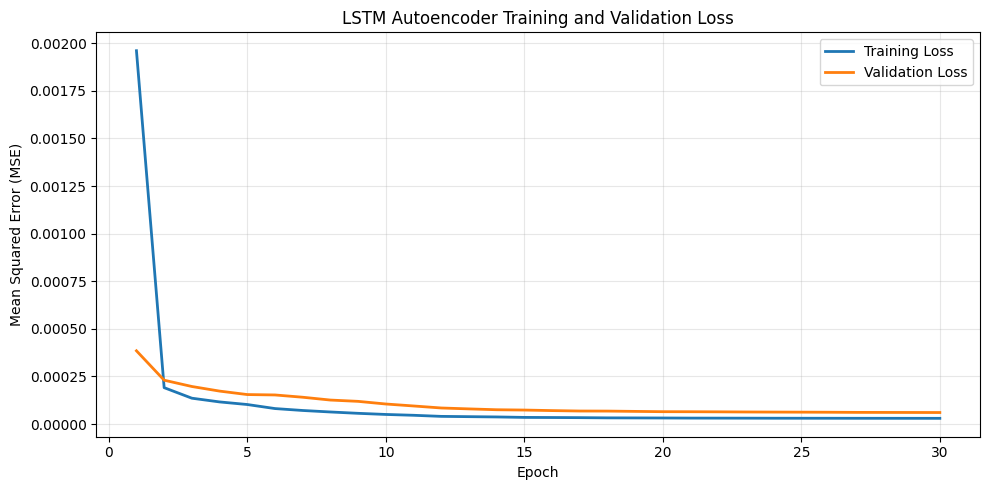

Best validation loss: 6.08153895882424e-05
Best epoch: 30
Training loss plot saved to:
/content/IAQ_Anomaly_Detection/plots/training_validation_loss.png


In [ ]:
# ============================================================
# STEP 13: VISUALIZE TRAINING AND VALIDATION LOSS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load saved training history
history_path = RESULTS_DIR / "training_history.csv"

training_history = pd.read_csv(history_path)

epochs = np.arange(1, len(training_history) + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    training_history["loss"],
    label="Training Loss",
    linewidth=2
)

plt.plot(
    epochs,
    training_history["val_loss"],
    label="Validation Loss",
    linewidth=2
)

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (MSE)")
plt.title("LSTM Autoencoder Training and Validation Loss")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plot_path = PLOTS_DIR / "training_validation_loss.png"

plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Best validation loss:",
      training_history["val_loss"].min())

print("Best epoch:",
      training_history["val_loss"].idxmin() + 1)

print("Training loss plot saved to:")
print(plot_path)

Calculating training reconstruction errors...
Calculating validation reconstruction errors...
Calculating test reconstruction errors...

RECONSTRUCTION ERROR STATISTICS


,Dataset,Mean,Median,95th Percentile,99th Percentile,Maximum
0,Training,0.000030,0.000004,0.000148,0.000620,0.002836
1,Validation,0.000061,0.000025,0.000167,0.001141,0.004446
2,Testing,0.000320,0.000136,0.001338,0.004483,0.009903


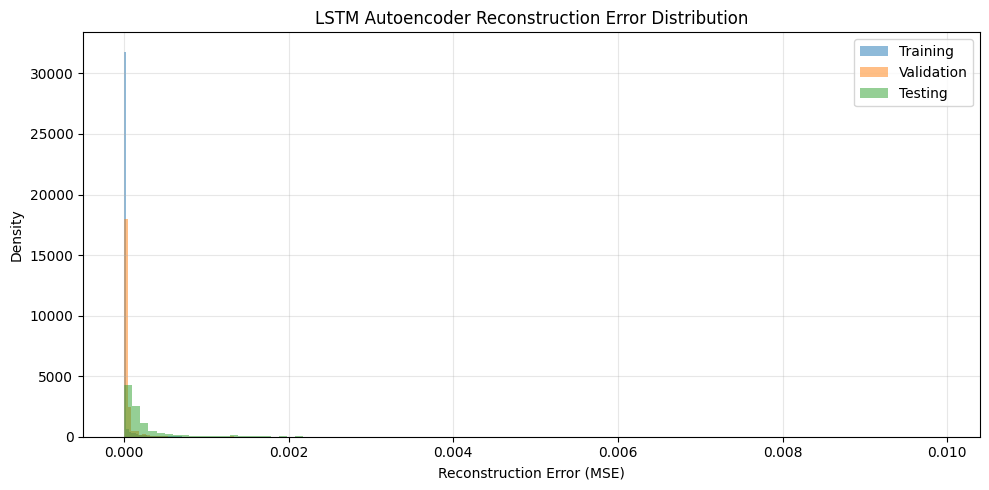

In [ ]:
# ============================================================
# STEP 14: CALCULATE RECONSTRUCTION ERRORS
# ============================================================

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

# Load best saved model
best_model = tf.keras.models.load_model(
    str(MODEL_DIR / "best_iaq_lstm_autoencoder.keras")
)

def calculate_reconstruction_errors(model, X, batch_size=256):

    errors = []

    for start in range(0, len(X), batch_size):

        batch = X[start:start + batch_size]

        reconstructed = model.predict(
            batch,
            batch_size=batch_size,
            verbose=0
        )

        batch_errors = np.mean(
            np.square(batch - reconstructed),
            axis=(1, 2)
        )

        errors.append(batch_errors)

    return np.concatenate(errors)


print("Calculating training reconstruction errors...")
train_errors = calculate_reconstruction_errors(
    best_model, X_train
)

print("Calculating validation reconstruction errors...")
val_errors = calculate_reconstruction_errors(
    best_model, X_val
)

print("Calculating test reconstruction errors...")
test_errors = calculate_reconstruction_errors(
    best_model, X_test
)

print("\n" + "=" * 55)
print("RECONSTRUCTION ERROR STATISTICS")
print("=" * 55)

error_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "Mean": [
        train_errors.mean(),
        val_errors.mean(),
        test_errors.mean()
    ],
    "Median": [
        np.median(train_errors),
        np.median(val_errors),
        np.median(test_errors)
    ],
    "95th Percentile": [
        np.percentile(train_errors, 95),
        np.percentile(val_errors, 95),
        np.percentile(test_errors, 95)
    ],
    "99th Percentile": [
        np.percentile(train_errors, 99),
        np.percentile(val_errors, 99),
        np.percentile(test_errors, 99)
    ],
    "Maximum": [
        train_errors.max(),
        val_errors.max(),
        test_errors.max()
    ]
})

display(error_summary)

# Plot reconstruction-error distributions
plt.figure(figsize=(10, 5))

for errors, label in [
    (train_errors, "Training"),
    (val_errors, "Validation"),
    (test_errors, "Testing")
]:
    plt.hist(
        errors,
        bins=100,
        alpha=0.5,
        density=True,
        label=label
    )

plt.xlabel("Reconstruction Error (MSE)")
plt.ylabel("Density")
plt.title("LSTM Autoencoder Reconstruction Error Distribution")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "reconstruction_error_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Anomaly threshold: 0.0011406003

Anomaly detection summary:


,Dataset,Total sequences,Detected anomalies,Anomaly percentage
0,Training,246009,537,0.218285
1,Validation,86282,863,1.000209
2,Testing,172564,11623,6.735472



Predictions saved to:
/content/IAQ_Anomaly_Detection/results/test_anomaly_predictions.csv


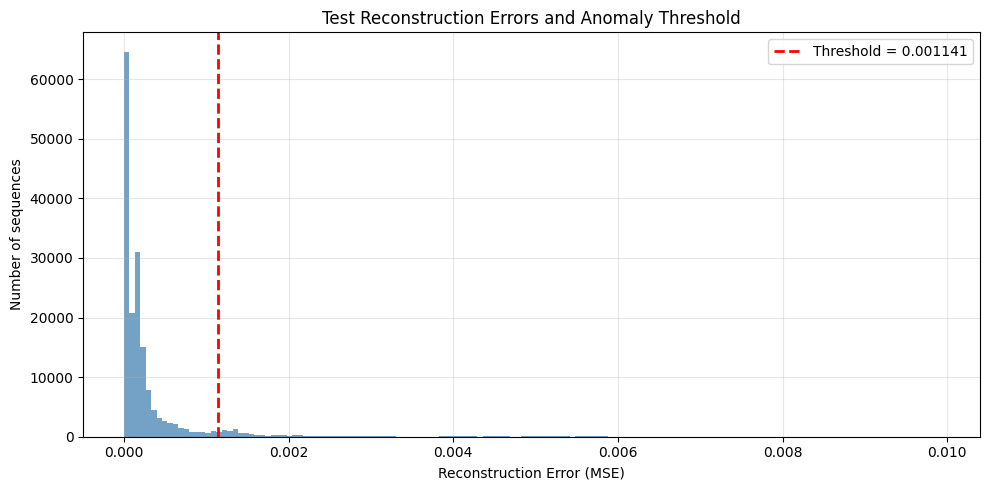

In [ ]:
# ============================================================
# STEP 15: THRESHOLD SELECTION AND ANOMALY DETECTION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Determine threshold using validation errors only
# ------------------------------------------------------------

THRESHOLD_PERCENTILE = 99

anomaly_threshold = np.percentile(
    val_errors,
    THRESHOLD_PERCENTILE
)

print("Anomaly threshold:", anomaly_threshold)


# ------------------------------------------------------------
# 2. Apply threshold to all dataset splits
# ------------------------------------------------------------

train_anomalies = train_errors > anomaly_threshold
val_anomalies = val_errors > anomaly_threshold
test_anomalies = test_errors > anomaly_threshold


# ------------------------------------------------------------
# 3. Summarize detection results
# ------------------------------------------------------------

summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "Total sequences": [
        len(train_errors),
        len(val_errors),
        len(test_errors)
    ],
    "Detected anomalies": [
        train_anomalies.sum(),
        val_anomalies.sum(),
        test_anomalies.sum()
    ]
})

summary["Anomaly percentage"] = (
    100 * summary["Detected anomalies"]
    / summary["Total sequences"]
)

print("\nAnomaly detection summary:")
display(summary)


# ------------------------------------------------------------
# 4. Save test predictions with timestamps
# ------------------------------------------------------------

test_results = test_metadata.copy()

test_results["reconstruction_error"] = test_errors
test_results["anomaly_threshold"] = anomaly_threshold
test_results["predicted_anomaly"] = test_anomalies.astype(int)

results_path = (
    RESULTS_DIR / "test_anomaly_predictions.csv"
)

test_results.to_csv(results_path, index=False)

print("\nPredictions saved to:")
print(results_path)


# ------------------------------------------------------------
# 5. Visualize threshold on test error distribution
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.hist(
    test_errors,
    bins=150,
    alpha=0.75,
    color="steelblue"
)

plt.axvline(
    anomaly_threshold,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Threshold = {anomaly_threshold:.6f}"
)

plt.xlabel("Reconstruction Error (MSE)")
plt.ylabel("Number of sequences")
plt.title("Test Reconstruction Errors and Anomaly Threshold")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "anomaly_threshold.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

ANOMALY DETECTION BY TEST DATE


,date,total_sequences,anomaly_sequences,mean_error,max_error,anomaly_pct
0,2023_06_04,86282,7012,0.000356,0.006090,8.126840
1,2023_06_05,86282,4611,0.000284,0.009903,5.344104


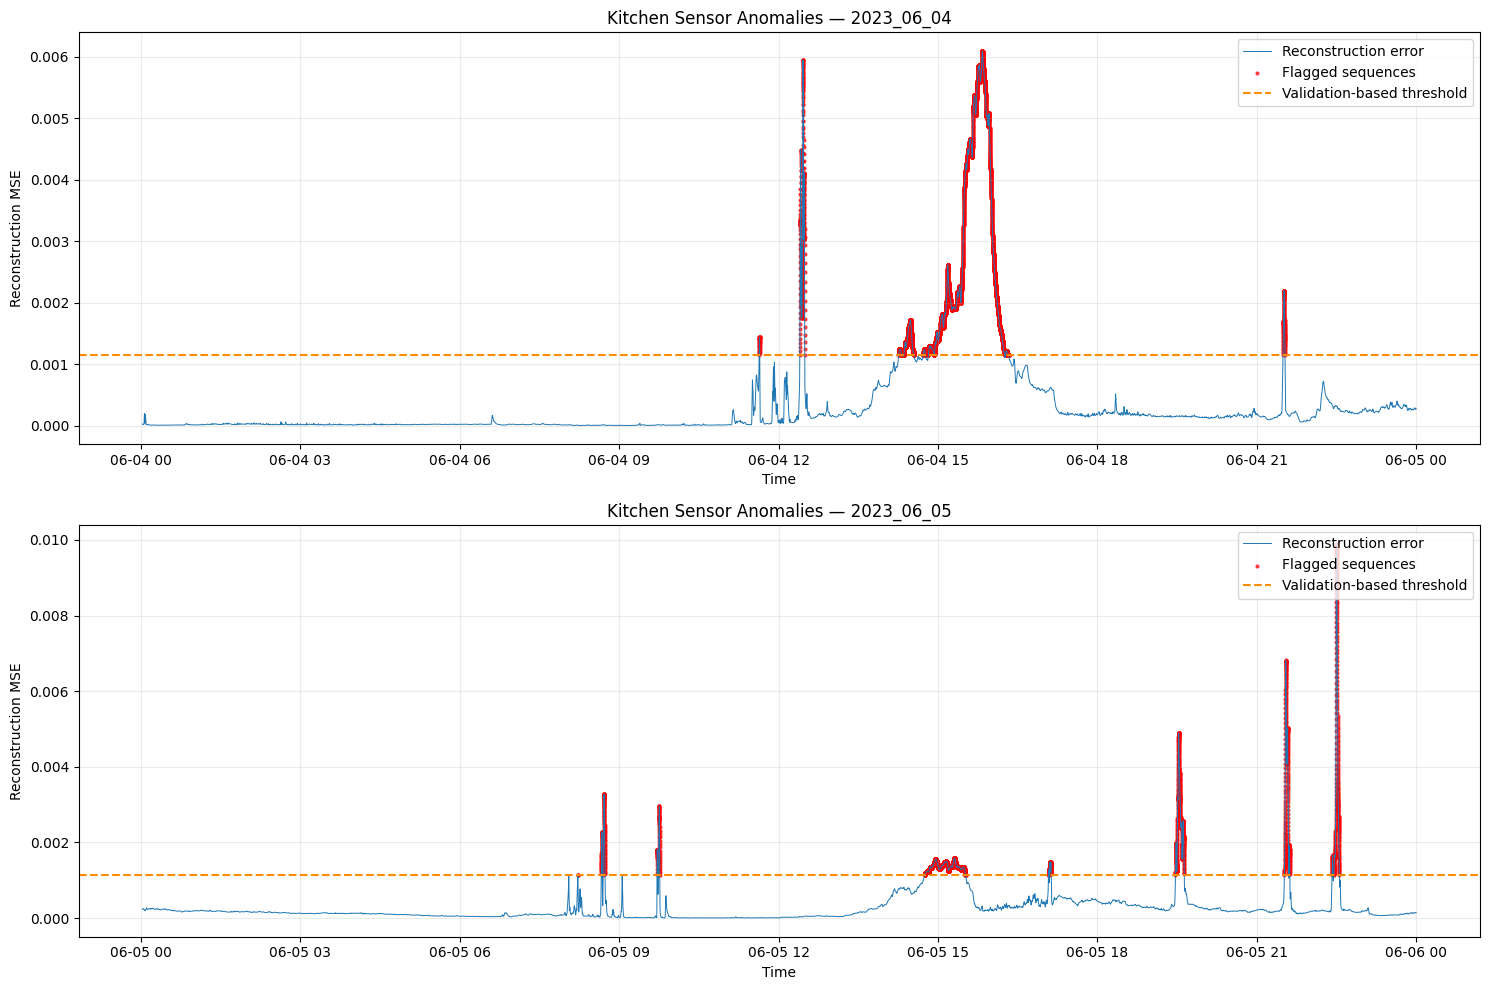


Plot saved to:
/content/IAQ_Anomaly_Detection/plots/test_anomalies_over_time.png


In [ ]:
# ============================================================
# STEP 16: VISUALIZE DETECTED ANOMALIES OVER TIME
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Use the predictions generated in STEP 15
results = test_results.copy()

results["timestamp"] = pd.to_datetime(results["timestamp"])

print("=" * 55)
print("ANOMALY DETECTION BY TEST DATE")
print("=" * 55)

daily_summary = (
    results.groupby("date")
    .agg(
        total_sequences=("predicted_anomaly", "size"),
        anomaly_sequences=("predicted_anomaly", "sum"),
        mean_error=("reconstruction_error", "mean"),
        max_error=("reconstruction_error", "max")
    )
    .reset_index()
)

daily_summary["anomaly_pct"] = (
    100 * daily_summary["anomaly_sequences"]
    / daily_summary["total_sequences"]
)

display(daily_summary)

# ------------------------------------------------------------
# Plot each test date separately
# ------------------------------------------------------------

test_dates = sorted(results["date"].unique())

fig, axes = plt.subplots(
    len(test_dates),
    1,
    figsize=(15, 5 * len(test_dates)),
    sharex=False
)

axes = np.atleast_1d(axes)

for ax, date in zip(axes, test_dates):

    day = results[
        results["date"] == date
    ].sort_values("timestamp")

    flagged = day[
        day["predicted_anomaly"] == 1
    ]

    ax.plot(
        day["timestamp"],
        day["reconstruction_error"],
        linewidth=0.7,
        label="Reconstruction error"
    )

    ax.scatter(
        flagged["timestamp"],
        flagged["reconstruction_error"],
        s=4,
        color="red",
        alpha=0.65,
        label="Flagged sequences"
    )

    ax.axhline(
        anomaly_threshold,
        color="darkorange",
        linestyle="--",
        linewidth=1.5,
        label="Validation-based threshold"
    )

    ax.set_title(f"Kitchen Sensor Anomalies — {date}")
    ax.set_xlabel("Time")
    ax.set_ylabel("Reconstruction MSE")
    ax.legend(loc="upper right")
    ax.grid(alpha=0.25)

plt.tight_layout()

plot_path = PLOTS_DIR / "test_anomalies_over_time.png"

plt.savefig(
    plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nPlot saved to:")
print(plot_path)

Total H1 annotations on test dates: 165

Activity annotations by date:


,0
ts,
2023_06_04,92
2023_06_05,73



Activity labels and timestamps:


,ts,Label,Customer
1229,2023-06-04 00:03:58,dining fan on,P1
1230,2023-06-04 00:04:12,eating dinner,P1
1231,2023-06-04 00:08:55,cleaning table,P1
1232,2023-06-04 00:12:27,dining fan off,P1
1233,2023-06-04 00:12:49,bedroom fan on,P1
1234,2023-06-04 00:18:10,bedroom fan off,P1
1235,2023-06-04 00:25:52,dining fan on,P1
1236,2023-06-04 00:31:11,eating dinner,P2
1237,2023-06-04 00:42:47,cleaning table,P2
1238,2023-06-04 00:45:29,washing dishes,P2



Anomaly detections near annotated activities:


,timestamp,activity,nearby_sequences,flagged_sequences,anomaly_percentage,maximum_error
0,2023-06-04 00:03:58,dining fan on,421,0,0.0,0.000195
1,2023-06-04 00:04:12,eating dinner,435,0,0.0,0.000195
2,2023-06-04 00:08:55,cleaning table,601,0,0.0,0.000195
3,2023-06-04 00:12:27,dining fan off,601,0,0.0,0.000021
4,2023-06-04 00:12:49,bedroom fan on,601,0,0.0,0.000016
5,2023-06-04 00:18:10,bedroom fan off,601,0,0.0,0.000013
6,2023-06-04 00:25:52,dining fan on,601,0,0.0,0.000009
7,2023-06-04 00:31:11,eating dinner,601,0,0.0,0.000008
8,2023-06-04 00:42:47,cleaning table,601,0,0.0,0.000011
9,2023-06-04 00:45:29,washing dishes,601,0,0.0,0.000015



Annotations with at least one flagged sequence: 27
Total annotations analyzed: 165


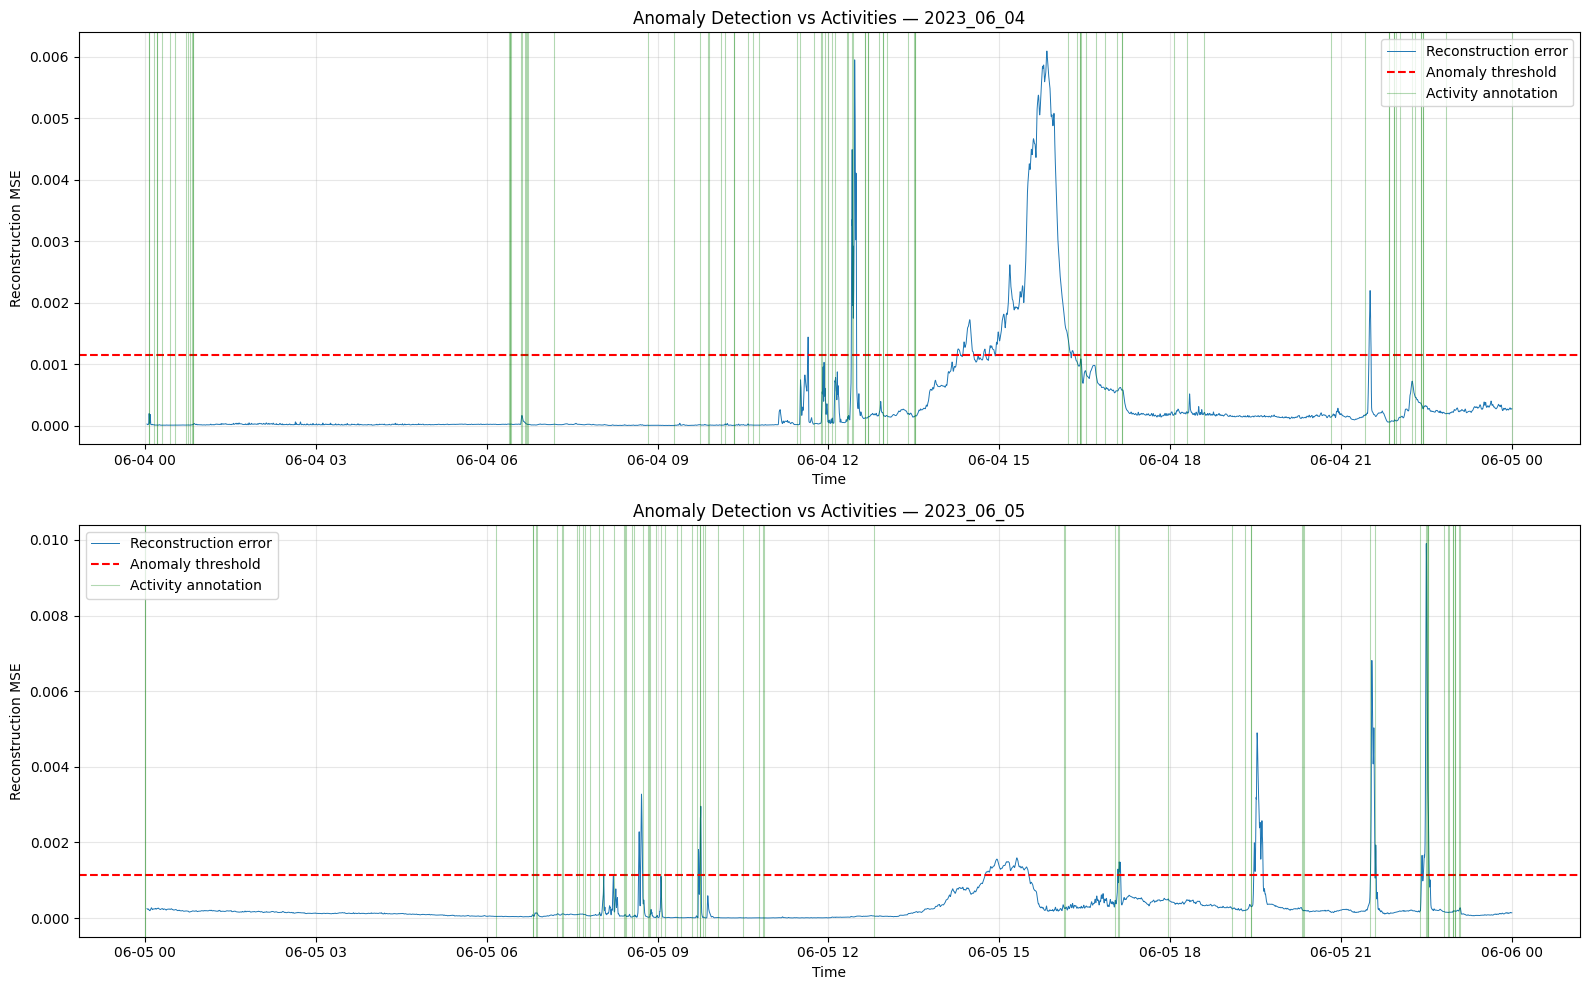


Plot saved to: /content/IAQ_Anomaly_Detection/plots/anomalies_vs_activities.png


In [ ]:
# ============================================================
# STEP 17: COMPARE ANOMALIES WITH DALTON ACTIVITY ANNOTATIONS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Load annotations
# ------------------------------------------------------------

annotations_path = METADATA_DIR / "Annotations_cleaned.csv"

activity_df = pd.read_csv(annotations_path, low_memory=False)

activity_df["ts"] = pd.to_datetime(
    activity_df["ts"], errors="coerce"
)

# H1 activities on our two test dates
test_dates = ["2023_06_04", "2023_06_05"]

h1_activities = activity_df[
    (activity_df["Site"].astype(str).str.strip() == "H1") &
    (
        activity_df["ts"].dt.strftime("%Y_%m_%d")
        .isin(test_dates)
    )
].copy()

h1_activities = h1_activities.sort_values("ts")

print("Total H1 annotations on test dates:",
      len(h1_activities))

print("\nActivity annotations by date:")
display(
    h1_activities.groupby(
        h1_activities["ts"].dt.strftime("%Y_%m_%d")
    ).size()
)

print("\nActivity labels and timestamps:")
display(
    h1_activities[
        ["ts", "Label", "Customer"]
    ].head(30)
)


# ------------------------------------------------------------
# 2. Summarize anomaly activity near annotations
# ------------------------------------------------------------

results = test_results.copy()

results["timestamp"] = pd.to_datetime(
    results["timestamp"]
)

comparison_records = []

# For each activity, inspect a +/- 5-minute interval
for _, activity in h1_activities.iterrows():

    activity_time = activity["ts"]

    start_time = activity_time - pd.Timedelta(minutes=5)
    end_time = activity_time + pd.Timedelta(minutes=5)

    nearby = results[
        (results["timestamp"] >= start_time) &
        (results["timestamp"] <= end_time)
    ]

    if len(nearby) == 0:
        continue

    comparison_records.append({
        "timestamp": activity_time,
        "activity": activity["Label"],
        "nearby_sequences": len(nearby),
        "flagged_sequences": int(
            nearby["predicted_anomaly"].sum()
        ),
        "anomaly_percentage": round(
            100 * nearby["predicted_anomaly"].mean(), 2
        ),
        "maximum_error": nearby[
            "reconstruction_error"
        ].max()
    })

activity_comparison = pd.DataFrame(comparison_records)

print("\nAnomaly detections near annotated activities:")

display(activity_comparison.head(30))

if not activity_comparison.empty:
    print("\nAnnotations with at least one flagged sequence:",
          (activity_comparison["flagged_sequences"] > 0).sum())

    print("Total annotations analyzed:",
          len(activity_comparison))


# ------------------------------------------------------------
# 3. Plot anomaly errors and annotated activities
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 1, figsize=(16, 10)
)

for ax, date in zip(axes, test_dates):

    day_results = results[
        results["date"] == date
    ].sort_values("timestamp")

    day_activities = h1_activities[
        h1_activities["ts"].dt.strftime("%Y_%m_%d") == date
    ]

    ax.plot(
        day_results["timestamp"],
        day_results["reconstruction_error"],
        linewidth=0.7,
        label="Reconstruction error"
    )

    ax.axhline(
        anomaly_threshold,
        color="red",
        linestyle="--",
        label="Anomaly threshold"
    )

    for j, (_, activity) in enumerate(day_activities.iterrows()):

        ax.axvline(
            activity["ts"],
            color="green",
            linewidth=0.8,
            alpha=0.3,
            label="Activity annotation" if j == 0 else None
        )

    ax.set_title(f"Anomaly Detection vs Activities — {date}")
    ax.set_xlabel("Time")
    ax.set_ylabel("Reconstruction MSE")
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()

plot_path = PLOTS_DIR / "anomalies_vs_activities.png"

plt.savefig(
    plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nPlot saved to:", plot_path)

In [ ]:
# ============================================================
# STEP 18A: PREPARE SYNTHETIC ANOMALY EVALUATION DATA
# ============================================================

import numpy as np
import pandas as pd

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

# Use non-overlapping 60-second sequences from test dates
# This reduces dependence between evaluation samples.

non_overlap_indices = []

for date in sorted(test_metadata["date"].unique()):

    date_indices = np.flatnonzero(
        test_metadata["date"].to_numpy() == date
    )

    non_overlap_indices.extend(
        date_indices[::WINDOW_SIZE].tolist()
    )

non_overlap_indices = np.array(
    non_overlap_indices, dtype=int
)

# Retain only naturally low-error candidate baseline windows
# These are proxy-normal samples, not verified normal labels.

baseline_indices = non_overlap_indices[
    test_errors[non_overlap_indices] <= anomaly_threshold
]

# Limit evaluation size for efficient experimentation
MAX_EVAL_SAMPLES = 2000

if len(baseline_indices) > MAX_EVAL_SAMPLES:
    baseline_indices = rng.choice(
        baseline_indices,
        size=MAX_EVAL_SAMPLES,
        replace=False
    )

baseline_indices = np.sort(baseline_indices)

X_eval_baseline = X_test[baseline_indices].copy()

print("=" * 55)
print("SYNTHETIC ANOMALY EVALUATION PREPARATION")
print("=" * 55)

print("Non-overlapping candidate windows:",
      len(non_overlap_indices))

print("Low-error baseline windows:",
      len(baseline_indices))

print("Evaluation array shape:",
      X_eval_baseline.shape)

print("All values finite:",
      np.isfinite(X_eval_baseline).all())

print("\nImportant: These samples are proxy-normal,")
print("not independently verified normal conditions.")

SYNTHETIC ANOMALY EVALUATION PREPARATION
Non-overlapping candidate windows: 2878
Low-error baseline windows: 2000
Evaluation array shape: (2000, 60, 10)
All values finite: True

Important: These samples are proxy-normal,
not independently verified normal conditions.


In [ ]:
# ============================================================
# STEP 18B: GENERATE SYNTHETIC SENSOR ANOMALIES
# ============================================================

import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

# Original low-error sequences
X_normal = X_eval_baseline.copy()

# Copies into which anomalies will be injected
X_synthetic = X_eval_baseline.copy()

N = len(X_synthetic)
SEQ_LEN = X_synthetic.shape[1]
N_FEATURES = X_synthetic.shape[2]

anomaly_types = []

# Three types of artificial disturbance
types = ["spike", "sustained_shift", "noise"]

for i in range(N):

    anomaly_type = types[i % len(types)]
    anomaly_types.append(anomaly_type)

    # Modify 1-3 randomly selected sensor features
    features_to_modify = rng.choice(
        N_FEATURES,
        size=rng.integers(1, 4),
        replace=False
    )

    if anomaly_type == "spike":

        # Short, large sensor spike lasting 5-10 seconds
        duration = int(rng.integers(5, 11))
        start = int(rng.integers(0, SEQ_LEN - duration + 1))

        amplitude = rng.uniform(0.5, 1.0)

        X_synthetic[
            i,
            start:start + duration,
            features_to_modify
        ] += amplitude

    elif anomaly_type == "sustained_shift":

        # Sustained abnormal shift lasting 20-40 seconds
        duration = int(rng.integers(20, 41))
        start = int(rng.integers(0, SEQ_LEN - duration + 1))

        amplitude = rng.uniform(0.25, 0.6)

        X_synthetic[
            i,
            start:start + duration,
            features_to_modify
        ] += amplitude

    elif anomaly_type == "noise":

        # High-frequency sensor noise throughout the window
        noise = rng.normal(
            loc=0.0,
            scale=0.3,
            size=(SEQ_LEN, len(features_to_modify))
        )

        X_synthetic[i][
            :,
            features_to_modify
        ] += noise

# Labels:
# 0 = unmodified proxy-normal sample
# 1 = synthetically modified sample

X_synthetic_eval = np.concatenate(
    [X_normal, X_synthetic],
    axis=0
).astype(np.float32)

y_synthetic_eval = np.concatenate(
    [
        np.zeros(N, dtype=int),
        np.ones(N, dtype=int)
    ]
)

# Shuffle evaluation data and labels together
permutation = rng.permutation(len(X_synthetic_eval))

X_synthetic_eval = X_synthetic_eval[permutation]
y_synthetic_eval = y_synthetic_eval[permutation]

print("=" * 55)
print("SYNTHETIC ANOMALY DATASET")
print("=" * 55)

print("Evaluation shape:", X_synthetic_eval.shape)

print("Proxy-normal samples:",
      np.sum(y_synthetic_eval == 0))

print("Synthetic anomalous samples:",
      np.sum(y_synthetic_eval == 1))

print("\nAnomaly types:")
print(pd.Series(anomaly_types).value_counts())

print("\nAll values finite:",
      np.isfinite(X_synthetic_eval).all())

SYNTHETIC ANOMALY DATASET
Evaluation shape: (4000, 60, 10)
Proxy-normal samples: 2000
Synthetic anomalous samples: 2000

Anomaly types:
spike              667
sustained_shift    667
noise              666
Name: count, dtype: int64

All values finite: True


Evaluating synthetic anomaly dataset...

SYNTHETIC ANOMALY DETECTION RESULTS
Accuracy : 0.9998 (99.98%)
Precision: 1.0000 (100.00%)
Recall   : 0.9995 (99.95%)
F1-Score : 0.9997 (99.97%)

Classification report:
                   precision    recall  f1-score   support

     Proxy-normal       1.00      1.00      1.00      2000
Synthetic anomaly       1.00      1.00      1.00      2000

         accuracy                           1.00      4000
        macro avg       1.00      1.00      1.00      4000
     weighted avg       1.00      1.00      1.00      4000



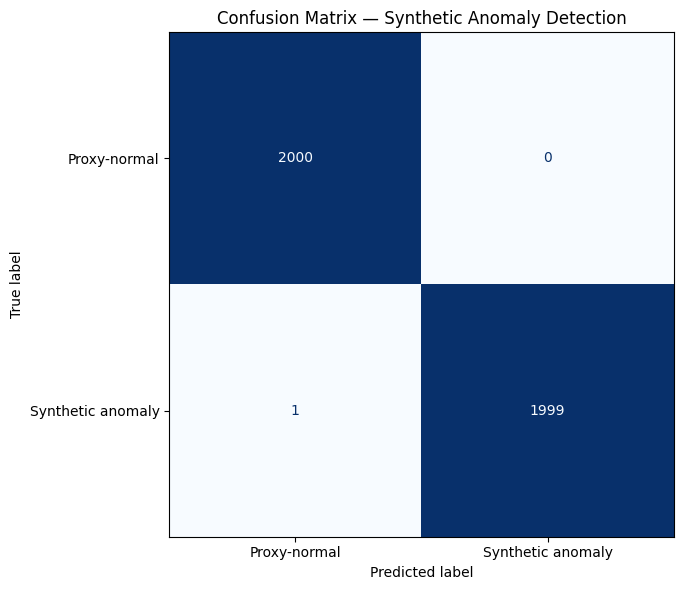


Metrics saved to: /content/IAQ_Anomaly_Detection/results/synthetic_evaluation_metrics.csv
Confusion matrix saved to: /content/IAQ_Anomaly_Detection/plots/synthetic_confusion_matrix.png


In [ ]:
# ============================================================
# STEP 18C: SYNTHETIC ANOMALY DETECTION EVALUATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# ------------------------------------------------------------
# 1. Calculate reconstruction errors
# ------------------------------------------------------------

print("Evaluating synthetic anomaly dataset...")

synthetic_errors = calculate_reconstruction_errors(
    best_model,
    X_synthetic_eval,
    batch_size=256
)

# ------------------------------------------------------------
# 2. Apply the EXISTING anomaly threshold
# ------------------------------------------------------------

y_pred_synthetic = (
    synthetic_errors > anomaly_threshold
).astype(int)

# ------------------------------------------------------------
# 3. Calculate classification metrics
# ------------------------------------------------------------

accuracy = accuracy_score(
    y_synthetic_eval,
    y_pred_synthetic
)

precision = precision_score(
    y_synthetic_eval,
    y_pred_synthetic,
    zero_division=0
)

recall = recall_score(
    y_synthetic_eval,
    y_pred_synthetic,
    zero_division=0
)

f1 = f1_score(
    y_synthetic_eval,
    y_pred_synthetic,
    zero_division=0
)

print("\n" + "=" * 55)
print("SYNTHETIC ANOMALY DETECTION RESULTS")
print("=" * 55)

print(f"Accuracy : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision: {precision:.4f} ({precision * 100:.2f}%)")
print(f"Recall   : {recall:.4f} ({recall * 100:.2f}%)")
print(f"F1-Score : {f1:.4f} ({f1 * 100:.2f}%)")

print("\nClassification report:")

print(
    classification_report(
        y_synthetic_eval,
        y_pred_synthetic,
        target_names=[
            "Proxy-normal",
            "Synthetic anomaly"
        ],
        zero_division=0
    )
)

# ------------------------------------------------------------
# 4. Confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    y_synthetic_eval,
    y_pred_synthetic,
    labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Proxy-normal",
        "Synthetic anomaly"
    ]
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Confusion Matrix — Synthetic Anomaly Detection")
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "synthetic_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 5. Save evaluation metrics
# ------------------------------------------------------------

metrics_df = pd.DataFrame([{
    "accuracy": accuracy,
    "precision": precision,
    "recall": recall,
    "f1_score": f1,
    "threshold": float(anomaly_threshold),
    "total_samples": len(y_synthetic_eval),
    "synthetic_anomalies": int(
        np.sum(y_synthetic_eval == 1)
    )
}])

metrics_path = (
    RESULTS_DIR / "synthetic_evaluation_metrics.csv"
)

metrics_df.to_csv(
    metrics_path,
    index=False
)

print("\nMetrics saved to:", metrics_path)
print(
    "Confusion matrix saved to:",
    PLOTS_DIR / "synthetic_confusion_matrix.png"
)

In [ ]:
# ============================================================
# STEP 19: FINAL PROJECT EVALUATION SUMMARY
# ============================================================

import pandas as pd

final_summary = pd.DataFrame([
    {
        "Evaluation": "Model training",
        "Metric": "Final training MSE",
        "Value": float(history.history["loss"][-1])
    },
    {
        "Evaluation": "Model validation",
        "Metric": "Best validation MSE",
        "Value": float(min(history.history["val_loss"]))
    },
    {
        "Evaluation": "Real DALTON test",
        "Metric": "Test sequences",
        "Value": int(len(test_errors))
    },
    {
        "Evaluation": "Real DALTON test",
        "Metric": "Flagged sequences",
        "Value": int(test_anomalies.sum())
    },
    {
        "Evaluation": "Real DALTON test",
        "Metric": "Anomaly flag rate (%)",
        "Value": float(100 * test_anomalies.mean())
    },
    {
        "Evaluation": "Activity association",
        "Metric": "Annotated activities",
        "Value": int(len(h1_activities))
    },
    {
        "Evaluation": "Activity association",
        "Metric": "Annotations near flagged sequences",
        "Value": int(
            (activity_comparison["flagged_sequences"] > 0).sum()
        )
    },
    {
        "Evaluation": "Synthetic evaluation",
        "Metric": "Accuracy (%)",
        "Value": float(accuracy * 100)
    },
    {
        "Evaluation": "Synthetic evaluation",
        "Metric": "Precision (%)",
        "Value": float(precision * 100)
    },
    {
        "Evaluation": "Synthetic evaluation",
        "Metric": "Recall (%)",
        "Value": float(recall * 100)
    },
    {
        "Evaluation": "Synthetic evaluation",
        "Metric": "F1-score (%)",
        "Value": float(f1 * 100)
    }
])

display(final_summary)

summary_path = RESULTS_DIR / "final_project_summary.csv"
final_summary.to_csv(summary_path, index=False)

print("Final summary saved to:", summary_path)

,Evaluation,Metric,Value
0,Model training,Final training MSE,0.000030
1,Model validation,Best validation MSE,0.000061
2,Real DALTON test,Test sequences,172564.000000
3,Real DALTON test,Flagged sequences,11623.000000
4,Real DALTON test,Anomaly flag rate (%),6.735472
5,Activity association,Annotated activities,165.000000
6,Activity association,Annotations near flagged sequences,27.000000
7,Synthetic evaluation,Accuracy (%),99.975000
8,Synthetic evaluation,Precision (%),100.000000
9,Synthetic evaluation,Recall (%),99.950000


Final summary saved to: /content/IAQ_Anomaly_Detection/results/final_project_summary.csv


In [ ]:
# ============================================================
# STEP 20: SAVE AND BACK UP PROJECT RESULTS
# ============================================================

import json
import shutil
import joblib
from pathlib import Path
from google.colab import files

# Save fitted preprocessing scaler
joblib.dump(
    scaler,
    MODEL_DIR / "minmax_scaler.joblib"
)

# Save experiment configuration
config = {
    "project": "Indoor Air Quality Anomaly Detection",
    "dataset": "DALTON",
    "site": "H1",
    "sensor": "41_Kitchen.csv",
    "features": FEATURES,
    "window_size": WINDOW_SIZE,
    "train_dates": TRAIN_DATES,
    "validation_dates": VAL_DATES,
    "test_dates": TEST_DATES,
    "anomaly_threshold": float(anomaly_threshold),
    "threshold_method": "99th percentile of validation MSE",
    "model": "LSTM Autoencoder"
}

with open(
    PROJECT_DIR / "experiment_config.json", "w"
) as f:
    json.dump(config, f, indent=4)

# Archive outputs without copying the entire DALTON dataset
backup_dir = Path("/content/IAQ_Project_Backup")

backup_dir.mkdir(exist_ok=True)

for folder in ["models", "results", "plots"]:
    source = PROJECT_DIR / folder
    destination = backup_dir / folder

    if destination.exists():
        shutil.rmtree(destination)

    shutil.copytree(source, destination)

shutil.copy2(
    PROJECT_DIR / "experiment_config.json",
    backup_dir / "experiment_config.json"
)

zip_path = shutil.make_archive(
    "/content/IAQ_Project_Backup",
    "zip",
    backup_dir
)

print("Project backup created successfully!")
print("Backup:", zip_path)

print("\nFiles included:")
for file in sorted(backup_dir.rglob("*")):
    if file.is_file():
        print("-", file.relative_to(backup_dir))

# Download backup to your computer
files.download(zip_path)

Project backup created successfully!
Backup: /content/IAQ_Project_Backup.zip

Files included:
- experiment_config.json
- models/best_iaq_lstm_autoencoder.keras
- models/minmax_scaler.joblib
- plots/anomalies_vs_activities.png
- plots/anomaly_threshold.png
- plots/reconstruction_error_distribution.png
- plots/synthetic_confusion_matrix.png
- plots/test_anomalies_over_time.png
- plots/training_validation_loss.png
- results/final_project_summary.csv
- results/synthetic_evaluation_metrics.csv
- results/test_anomaly_predictions.csv
- results/training_history.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ============================================================
# STEP 21: INDEPENDENT SYNTHETIC EVALUATION PREPARATION
# ============================================================

import numpy as np
import pandas as pd

rng_independent = np.random.default_rng(2026)

# ------------------------------------------------------------
# 1. Select non-overlapping windows from each test date
# ------------------------------------------------------------

candidate_indices = []

for date in sorted(test_metadata["date"].unique()):

    day_indices = np.flatnonzero(
        test_metadata["date"].to_numpy() == date
    )

    # Every 60th sequence to avoid overlapping windows
    candidate_indices.extend(
        day_indices[::WINDOW_SIZE]
    )

candidate_indices = np.array(
    candidate_indices,
    dtype=int
)

# ------------------------------------------------------------
# 2. Randomly select 2,000 without error-based filtering
# ------------------------------------------------------------

N_EVAL = 2000

assert len(candidate_indices) >= N_EVAL, (
    "Not enough independent candidate windows"
)

selected_indices = rng_independent.choice(
    candidate_indices,
    size=N_EVAL,
    replace=False
)

selected_indices = np.sort(selected_indices)

X_independent_base = X_test[selected_indices].copy()

independent_metadata = (
    test_metadata.iloc[selected_indices]
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 3. Inspect original model predictions
# ------------------------------------------------------------

original_errors = test_errors[selected_indices]

original_flagged = (
    original_errors > anomaly_threshold
)

print("=" * 60)
print("INDEPENDENT SYNTHETIC EVALUATION PREPARATION")
print("=" * 60)

print("Available non-overlapping windows:",
      len(candidate_indices))

print("Selected original windows:",
      len(selected_indices))

print("Evaluation shape:",
      X_independent_base.shape)

print("\nOriginal windows already flagged as anomalies:",
      int(original_flagged.sum()))

print("Original flag rate:",
      f"{100 * original_flagged.mean():.2f}%")

print("\nSelected windows per test date:")
print(independent_metadata["date"].value_counts())

print("\nAll values finite:",
      np.isfinite(X_independent_base).all())

INDEPENDENT SYNTHETIC EVALUATION PREPARATION
Available non-overlapping windows: 2878
Selected original windows: 2000
Evaluation shape: (2000, 60, 10)

Original windows already flagged as anomalies: 128
Original flag rate: 6.40%

Selected windows per test date:
date
2023_06_04    1004
2023_06_05     996
Name: count, dtype: int64

All values finite: True


In [ ]:
# ============================================================
# STEP 22: INDEPENDENT SYNTHETIC ANOMALY INJECTION
# ============================================================

import numpy as np
import pandas as pd

rng = np.random.default_rng(2026)

# ------------------------------------------------------------
# 1. Prepare original and synthetic sequences
# ------------------------------------------------------------

X_original = X_independent_base.copy()
X_modified = X_independent_base.copy()

N = len(X_modified)
SEQ_LEN = X_modified.shape[1]
N_FEATURES = X_modified.shape[2]

anomaly_types_independent = []

types = ["spike", "sustained_shift", "noise"]

# ------------------------------------------------------------
# 2. Inject disturbances
# ------------------------------------------------------------

for i in range(N):

    anomaly_type = types[i % len(types)]
    anomaly_types_independent.append(anomaly_type)

    features_to_modify = rng.choice(
        N_FEATURES,
        size=int(rng.integers(1, 4)),
        replace=False
    )

    if anomaly_type == "spike":

        duration = int(rng.integers(5, 11))
        start = int(
            rng.integers(0, SEQ_LEN - duration + 1)
        )

        amplitude = rng.uniform(0.5, 1.0)

        X_modified[
            i,
            start:start + duration,
            features_to_modify
        ] += amplitude

    elif anomaly_type == "sustained_shift":

        duration = int(rng.integers(20, 41))
        start = int(
            rng.integers(0, SEQ_LEN - duration + 1)
        )

        amplitude = rng.uniform(0.25, 0.6)

        X_modified[
            i,
            start:start + duration,
            features_to_modify
        ] += amplitude

    elif anomaly_type == "noise":

        noise = rng.normal(
            loc=0.0,
            scale=0.3,
            size=(SEQ_LEN, len(features_to_modify))
        )

        # Explicit indexing to modify the selected features
        X_modified[i][:, features_to_modify] += noise

# ------------------------------------------------------------
# 3. Construct labeled evaluation dataset
# ------------------------------------------------------------

X_independent_eval = np.concatenate(
    [X_original, X_modified],
    axis=0
).astype(np.float32)

y_independent_eval = np.concatenate([
    np.zeros(N, dtype=int),
    np.ones(N, dtype=int)
])

# Track disturbance types, including originals
evaluation_types = np.array(
    ["original"] * N + anomaly_types_independent
)

# ------------------------------------------------------------
# 4. Shuffle sequences and labels together
# ------------------------------------------------------------

permutation = rng.permutation(
    len(X_independent_eval)
)

X_independent_eval = X_independent_eval[permutation]
y_independent_eval = y_independent_eval[permutation]
evaluation_types = evaluation_types[permutation]

# ------------------------------------------------------------
# 5. Verify generated dataset
# ------------------------------------------------------------

print("=" * 60)
print("INDEPENDENT SYNTHETIC EVALUATION DATASET")
print("=" * 60)

print("Evaluation shape:", X_independent_eval.shape)

print("Original sequences:",
      np.sum(y_independent_eval == 0))

print("Modified sequences:",
      np.sum(y_independent_eval == 1))

print("\nEvaluation sample types:")
print(pd.Series(evaluation_types).value_counts())

print("\nAll values finite:",
      np.isfinite(X_independent_eval).all())

print("\nExisting anomaly threshold:",
      anomaly_threshold)

INDEPENDENT SYNTHETIC EVALUATION DATASET
Evaluation shape: (4000, 60, 10)
Original sequences: 2000
Modified sequences: 2000

Evaluation sample types:
original           2000
spike               667
sustained_shift     667
noise               666
Name: count, dtype: int64

All values finite: True

Existing anomaly threshold: 0.0011406003


Evaluating independent synthetic dataset...

INDEPENDENT SYNTHETIC EVALUATION RESULTS
Accuracy : 96.80%
Precision: 93.98%
Recall   : 100.00%
F1-score : 96.90%

Classification report:
                           precision    recall  f1-score   support

Original (assumed normal)       1.00      0.94      0.97      2000
        Synthetic anomaly       0.94      1.00      0.97      2000

                 accuracy                           0.97      4000
                macro avg       0.97      0.97      0.97      4000
             weighted avg       0.97      0.97      0.97      4000


Confusion matrix counts:
True negatives : 1872
False positives: 128
False negatives: 0
True positives : 2000


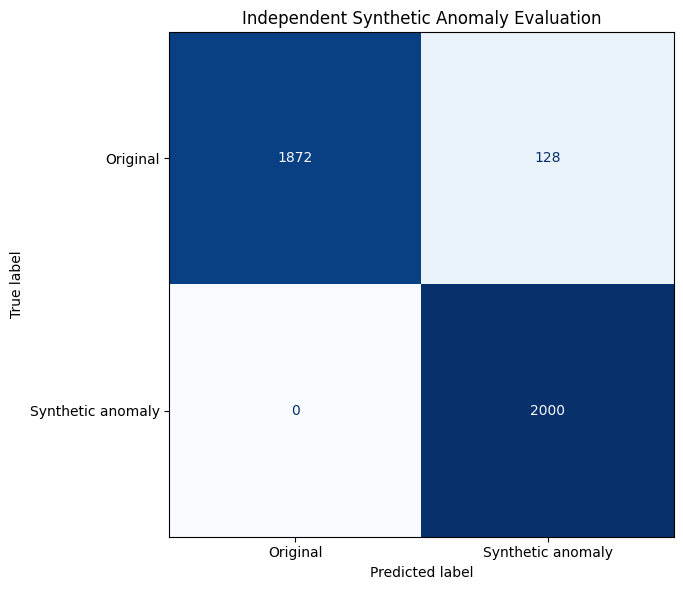


Detection results by sample type:


,type,total,flagged,mean_error,flagged_pct
0,noise,666,666,0.018345,100.0
1,original,2000,128,0.000314,6.4
2,spike,667,667,0.014502,100.0
3,sustained_shift,667,667,0.013984,100.0



Comparison with previous experiment:


,Metric,Previous synthetic evaluation,Unfiltered synthetic evaluation
0,Accuracy (%),99.975,96.800
1,Precision (%),100.000,93.985
2,Recall (%),99.950,100.000
3,F1-score (%),99.975,96.899



Evaluation files saved successfully!


In [ ]:
# ============================================================
# STEP 23: INDEPENDENT SYNTHETIC ANOMALY EVALUATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# ------------------------------------------------------------
# 1. Calculate reconstruction errors
# ------------------------------------------------------------

print("Evaluating independent synthetic dataset...")

independent_errors = calculate_reconstruction_errors(
    best_model,
    X_independent_eval,
    batch_size=256
)

# ------------------------------------------------------------
# 2. Apply existing validation-derived threshold
# ------------------------------------------------------------

y_pred_independent = (
    independent_errors > anomaly_threshold
).astype(int)

# ------------------------------------------------------------
# 3. Calculate classification metrics
# ------------------------------------------------------------

ind_accuracy = accuracy_score(
    y_independent_eval,
    y_pred_independent
)

ind_precision = precision_score(
    y_independent_eval,
    y_pred_independent,
    zero_division=0
)

ind_recall = recall_score(
    y_independent_eval,
    y_pred_independent,
    zero_division=0
)

ind_f1 = f1_score(
    y_independent_eval,
    y_pred_independent,
    zero_division=0
)

print("\n" + "=" * 60)
print("INDEPENDENT SYNTHETIC EVALUATION RESULTS")
print("=" * 60)

print(f"Accuracy : {ind_accuracy * 100:.2f}%")
print(f"Precision: {ind_precision * 100:.2f}%")
print(f"Recall   : {ind_recall * 100:.2f}%")
print(f"F1-score : {ind_f1 * 100:.2f}%")

print("\nClassification report:")

print(
    classification_report(
        y_independent_eval,
        y_pred_independent,
        target_names=[
            "Original (assumed normal)",
            "Synthetic anomaly"
        ],
        zero_division=0
    )
)

# ------------------------------------------------------------
# 4. Confusion matrix
# ------------------------------------------------------------

cm_independent = confusion_matrix(
    y_independent_eval,
    y_pred_independent,
    labels=[0, 1]
)

tn, fp, fn, tp = cm_independent.ravel()

print("\nConfusion matrix counts:")
print("True negatives :", tn)
print("False positives:", fp)
print("False negatives:", fn)
print("True positives :", tp)

fig, ax = plt.subplots(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_independent,
    display_labels=[
        "Original",
        "Synthetic anomaly"
    ]
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Independent Synthetic Anomaly Evaluation")
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "independent_synthetic_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 5. Detection performance by anomaly type
# ------------------------------------------------------------

type_results = pd.DataFrame({
    "type": evaluation_types,
    "true_label": y_independent_eval,
    "predicted_label": y_pred_independent,
    "reconstruction_error": independent_errors
})

type_summary = (
    type_results.groupby("type")
    .agg(
        total=("predicted_label", "size"),
        flagged=("predicted_label", "sum"),
        mean_error=("reconstruction_error", "mean")
    )
    .reset_index()
)

type_summary["flagged_pct"] = (
    100 * type_summary["flagged"]
    / type_summary["total"]
)

print("\nDetection results by sample type:")
display(type_summary)

# ------------------------------------------------------------
# 6. Compare with previous synthetic evaluation
# ------------------------------------------------------------

comparison_df = pd.DataFrame({
    "Metric": [
        "Accuracy (%)",
        "Precision (%)",
        "Recall (%)",
        "F1-score (%)"
    ],
    "Previous synthetic evaluation": [
        accuracy * 100,
        precision * 100,
        recall * 100,
        f1 * 100
    ],
    "Unfiltered synthetic evaluation": [
        ind_accuracy * 100,
        ind_precision * 100,
        ind_recall * 100,
        ind_f1 * 100
    ]
})

print("\nComparison with previous experiment:")
display(comparison_df.round(3))

# ------------------------------------------------------------
# 7. Save results
# ------------------------------------------------------------

type_summary.to_csv(
    RESULTS_DIR / "independent_anomaly_type_results.csv",
    index=False
)

comparison_df.to_csv(
    RESULTS_DIR / "synthetic_evaluation_comparison.csv",
    index=False
)

type_results.to_csv(
    RESULTS_DIR / "independent_synthetic_predictions.csv",
    index=False
)

print("\nEvaluation files saved successfully!")

Calculating feature-wise reconstruction errors...
Feature-error matrix: (172564, 10)

Feature-wise anomaly contribution:


,Feature,Mean MSE in flagged sequences,Contribution (%)
1,H,0.008924,37.423149
4,PMS10,0.003309,13.874194
2,PMS1,0.002484,10.418267
6,NO2,0.002281,9.566730
9,C2H5OH,0.002202,9.234318
5,CO2,0.001148,4.815320
3,PMS2_5,0.000957,4.012412
8,VoC,0.000942,3.950817
0,T,0.000800,3.353074
7,CO,0.000799,3.351717


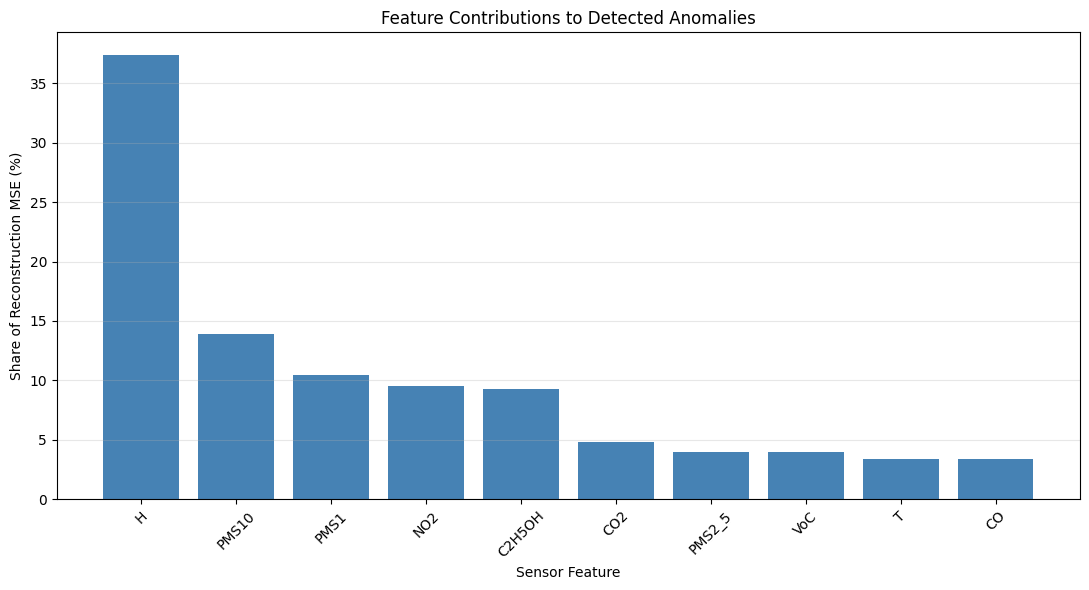


Feature analysis saved successfully!


In [ ]:
# ============================================================
# STEP 24: FEATURE-WISE ANOMALY ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Calculate feature-wise reconstruction errors
# ------------------------------------------------------------

feature_error_batches = []

BATCH_SIZE = 256

print("Calculating feature-wise reconstruction errors...")

for start in range(0, len(X_test), BATCH_SIZE):

    batch = X_test[start:start + BATCH_SIZE]

    reconstructed = best_model.predict(
        batch,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    # MSE for each feature, averaged across time
    feature_mse = np.mean(
        np.square(batch - reconstructed),
        axis=1
    )

    feature_error_batches.append(feature_mse)

feature_errors = np.concatenate(
    feature_error_batches,
    axis=0
)

print("Feature-error matrix:", feature_errors.shape)

# ------------------------------------------------------------
# 2. Analyze detected anomaly sequences
# ------------------------------------------------------------

anomaly_feature_errors = feature_errors[
    test_anomalies
]

mean_feature_errors = anomaly_feature_errors.mean(axis=0)

feature_summary = pd.DataFrame({
    "Feature": FEATURES,
    "Mean MSE in flagged sequences": mean_feature_errors
})

feature_summary["Contribution (%)"] = (
    100 * feature_summary["Mean MSE in flagged sequences"]
    / feature_summary["Mean MSE in flagged sequences"].sum()
)

feature_summary = feature_summary.sort_values(
    "Contribution (%)",
    ascending=False
)

print("\nFeature-wise anomaly contribution:")
display(feature_summary)

# ------------------------------------------------------------
# 3. Visualize feature contributions
# ------------------------------------------------------------

plt.figure(figsize=(11, 6))

plt.bar(
    feature_summary["Feature"],
    feature_summary["Contribution (%)"],
    color="steelblue"
)

plt.xlabel("Sensor Feature")
plt.ylabel("Share of Reconstruction MSE (%)")
plt.title("Feature Contributions to Detected Anomalies")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "feature_anomaly_contributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 4. Save feature summary
# ------------------------------------------------------------

feature_summary.to_csv(
    RESULTS_DIR / "feature_anomaly_contributions.csv",
    index=False
)

print("\nFeature analysis saved successfully!")

In [ ]:
# ============================================================
# STEP 25: IDENTIFY HIGH-ERROR ANOMALY EVENTS
# ============================================================

import numpy as np
import pandas as pd

# Use existing predictions from STEP 15
results = test_results.copy()

results["timestamp"] = pd.to_datetime(
    results["timestamp"]
)

results = results.sort_values(
    ["date", "timestamp"]
).reset_index(drop=True)

# Keep only flagged sequences
flagged = results[
    results["predicted_anomaly"] == 1
].copy()

# Start a new event when:
# 1. The recording date changes
# 2. There is a gap larger than 1 second between flagged windows

new_event = (
    flagged["date"].ne(flagged["date"].shift()) |
    flagged["timestamp"].diff().gt(
        pd.Timedelta(seconds=1)
    )
)

flagged["event_id"] = new_event.cumsum()

# Summarize each event
events = (
    flagged.groupby("event_id")
    .agg(
        date=("date", "first"),
        first_flagged=("timestamp", "min"),
        last_flagged=("timestamp", "max"),
        flagged_windows=("timestamp", "size"),
        peak_error=("reconstruction_error", "max"),
        mean_error=("reconstruction_error", "mean")
    )
    .reset_index()
)

# Approximate event duration in seconds
events["duration_seconds"] = (
    events["last_flagged"] -
    events["first_flagged"]
).dt.total_seconds() + 1

# Identify five highest-error events
top_events = (
    events.sort_values(
        "peak_error",
        ascending=False
    )
    .head(5)
    .copy()
)

print("=" * 60)
print("HIGH-ERROR ANOMALY EVENTS")
print("=" * 60)

print("\nTotal distinct anomaly events:", len(events))

print("\nTop 5 highest-error events:")
display(top_events)

print("\nAnomaly events per test date:")
display(
    events.groupby("date").agg(
        total_events=("event_id", "count"),
        total_flagged_windows=("flagged_windows", "sum"),
        longest_event_seconds=("duration_seconds", "max")
    )
)

# Save event summary
events.to_csv(
    RESULTS_DIR / "anomaly_event_summary.csv",
    index=False
)

top_events.to_csv(
    RESULTS_DIR / "top_anomaly_events.csv",
    index=False
)

print("\nEvent summaries saved successfully!")

HIGH-ERROR ANOMALY EVENTS

Total distinct anomaly events: 23

Top 5 highest-error events:


,event_id,date,first_flagged,last_flagged,flagged_windows,peak_error,mean_error,duration_seconds
22,23,2023_06_05,2023-06-05 22:26:50,2023-06-05 22:33:00,371,0.009903,0.004040,371.0
19,20,2023_06_05,2023-06-05 21:31:06,2023-06-05 21:35:53,288,0.006812,0.004045,288.0
7,8,2023_06_04,2023-06-04 14:55:56,2023-06-04 16:15:29,4774,0.006090,0.003150,4774.0
1,2,2023_06_04,2023-06-04 12:24:01,2023-06-04 12:29:35,335,0.005947,0.003342,335.0
18,19,2023_06_05,2023-06-05 19:28:05,2023-06-05 19:37:57,593,0.004900,0.002588,593.0



Anomaly events per test date:


,total_events,total_flagged_windows,longest_event_seconds
date,,,
2023_06_04,10,7012,4774.0
2023_06_05,13,4611,2764.0



Event summaries saved successfully!


Raw test recordings loaded successfully.

Sensor measurement comparison:


,event_id,date,feature,baseline_mean,event_mean,absolute_change,relative_change_pct
0,23,2023_06_05,T,36.259,36.871,0.612,1.687
1,23,2023_06_05,H,31.837,33.007,1.170,3.674
2,23,2023_06_05,PMS1,48.775,165.197,116.421,238.688
3,23,2023_06_05,PMS2_5,85.821,299.533,213.713,249.023
4,23,2023_06_05,PMS10,95.529,322.989,227.460,238.107
5,23,2023_06_05,CO2,509.578,1167.822,658.244,129.175
6,23,2023_06_05,NO2,88.102,473.636,385.534,437.599
7,23,2023_06_05,CO,304.404,516.433,212.029,69.654
8,23,2023_06_05,VoC,206.159,421.138,214.978,104.278
9,23,2023_06_05,C2H5OH,182.883,442.941,260.059,142.200


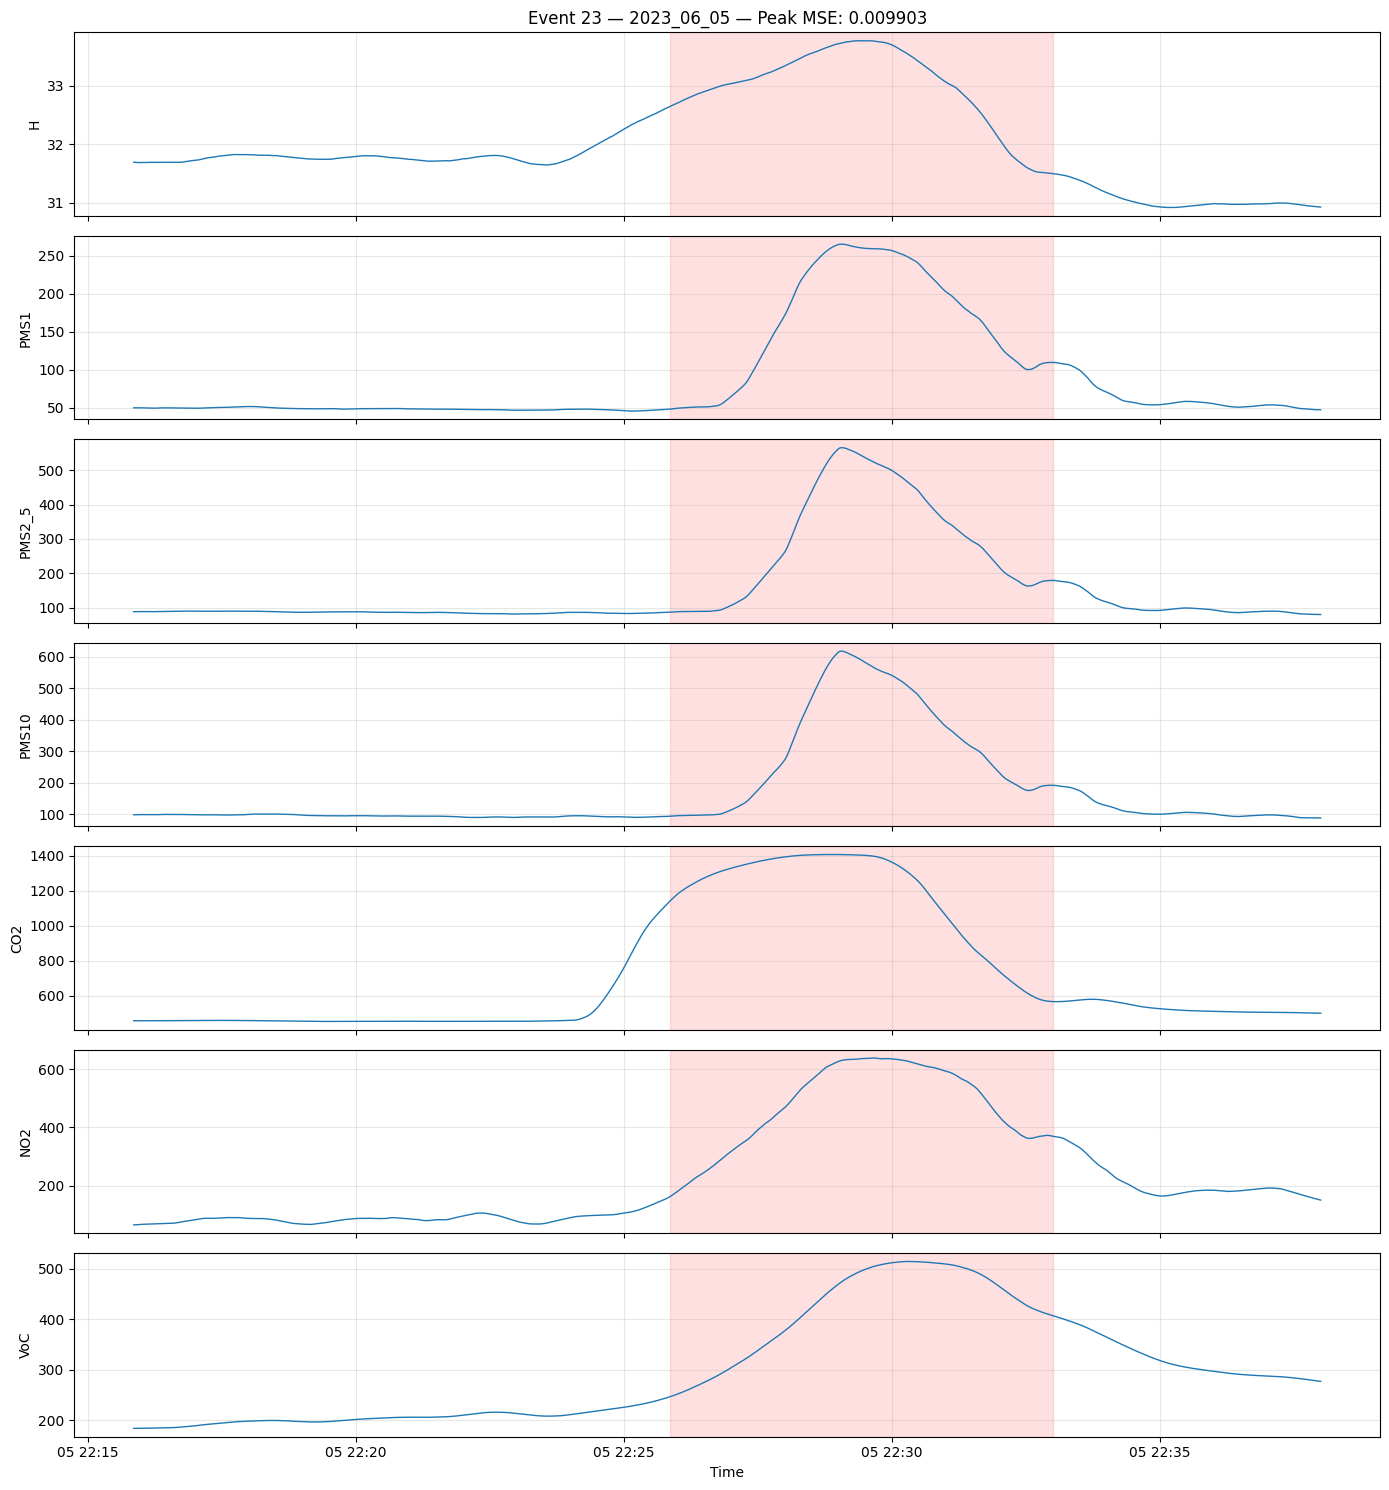

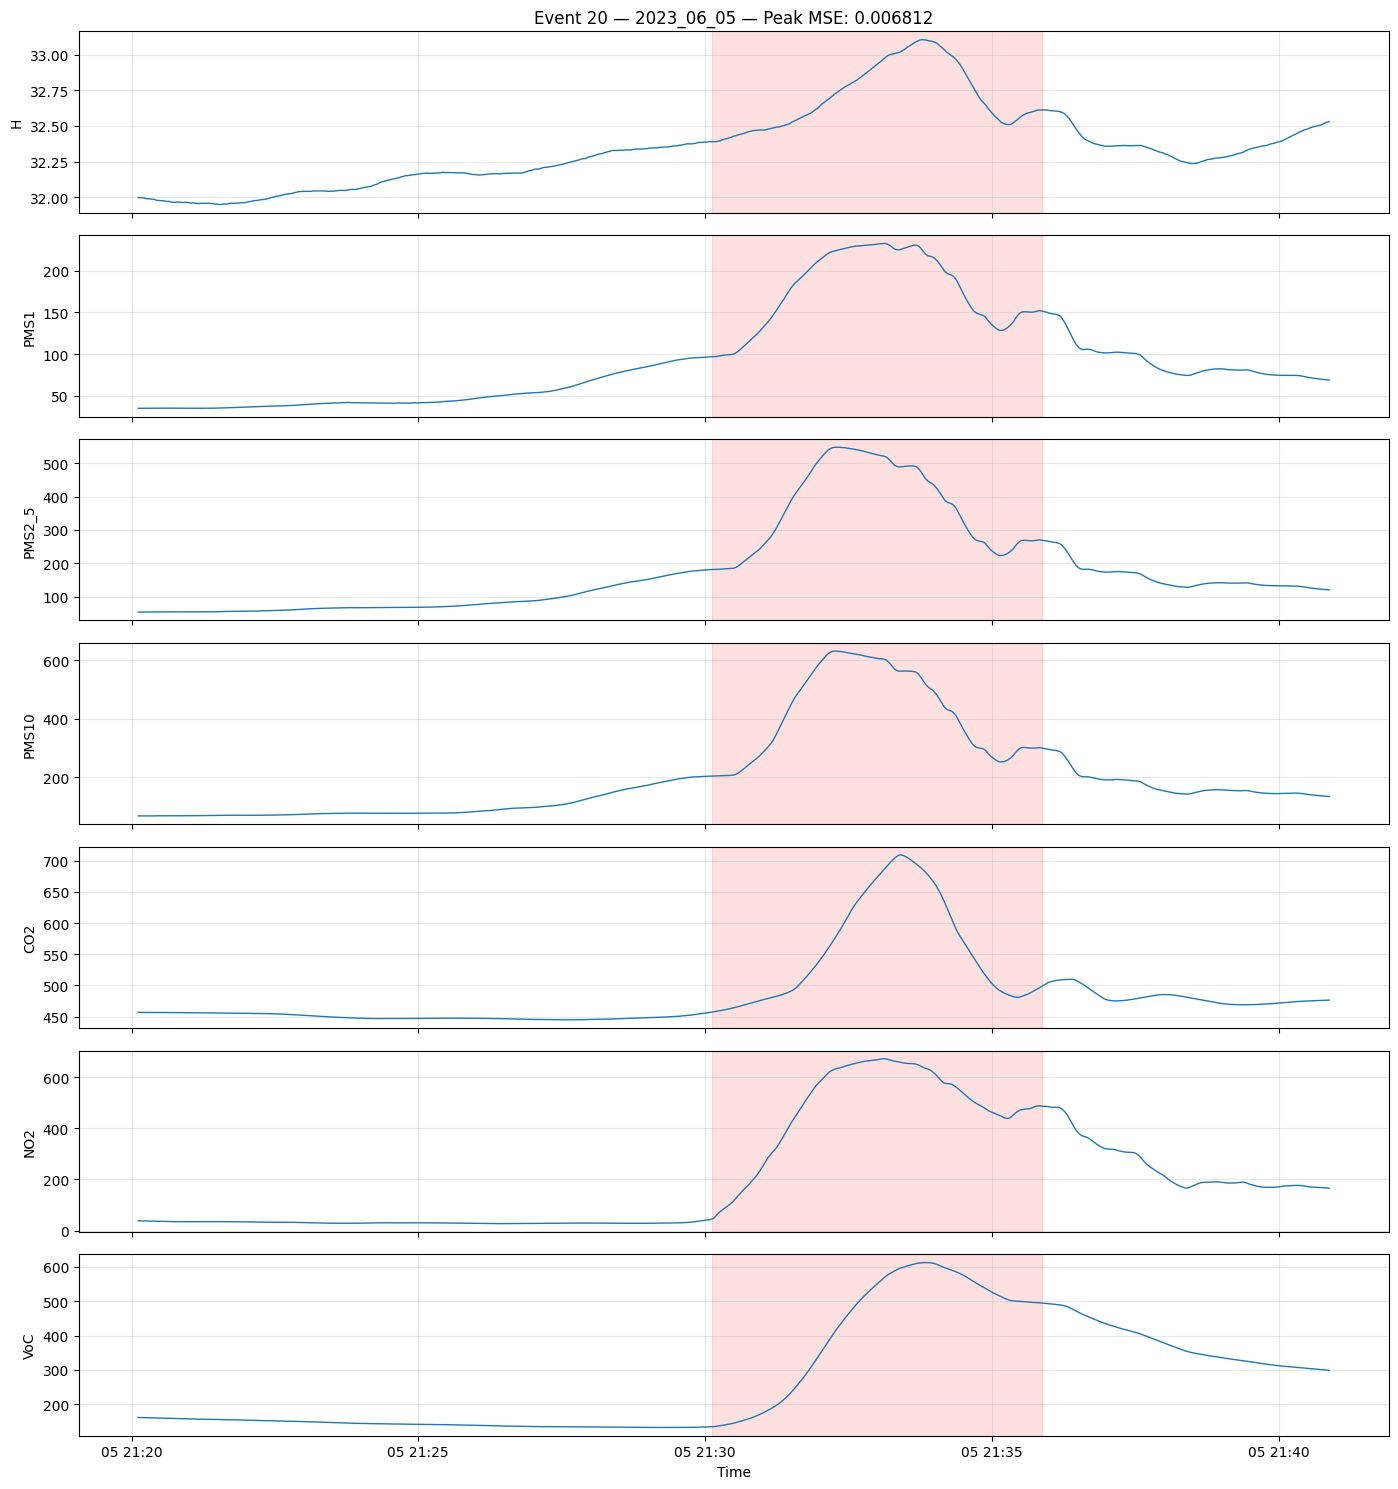

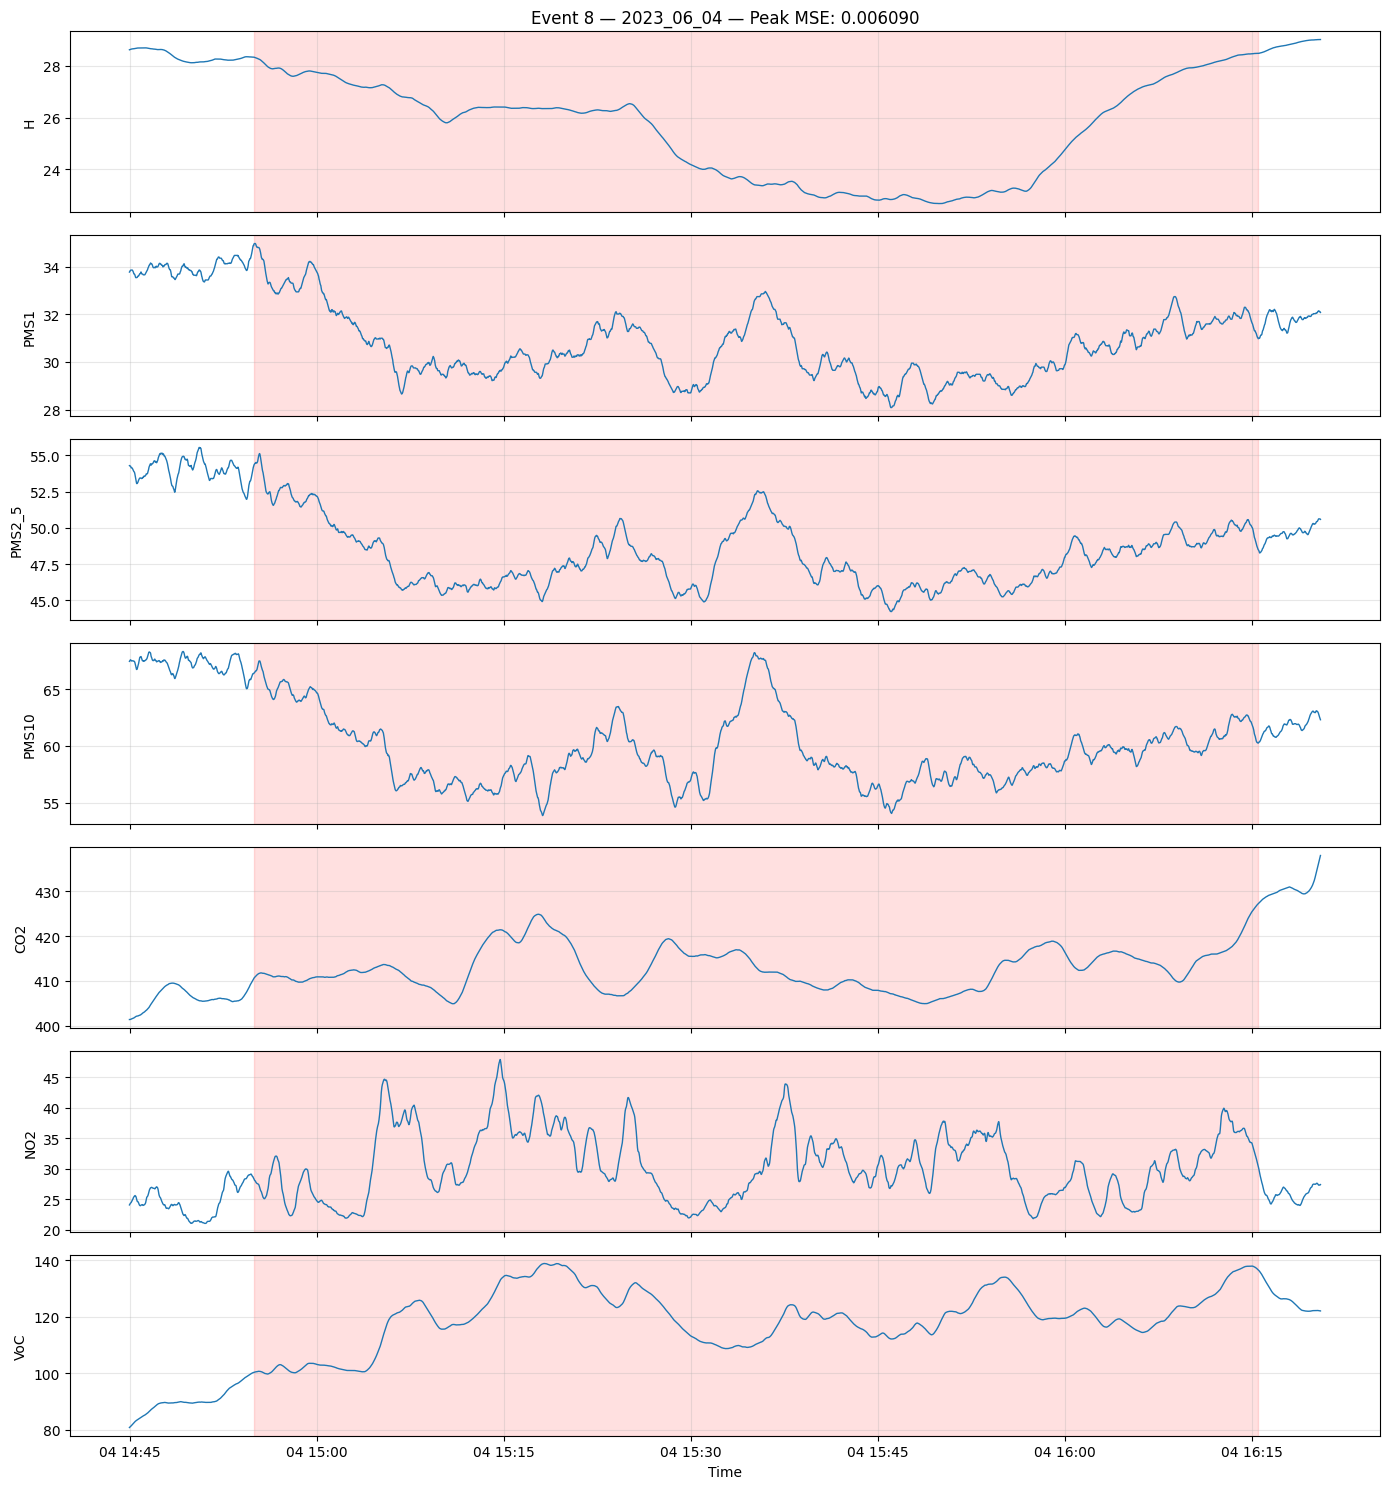

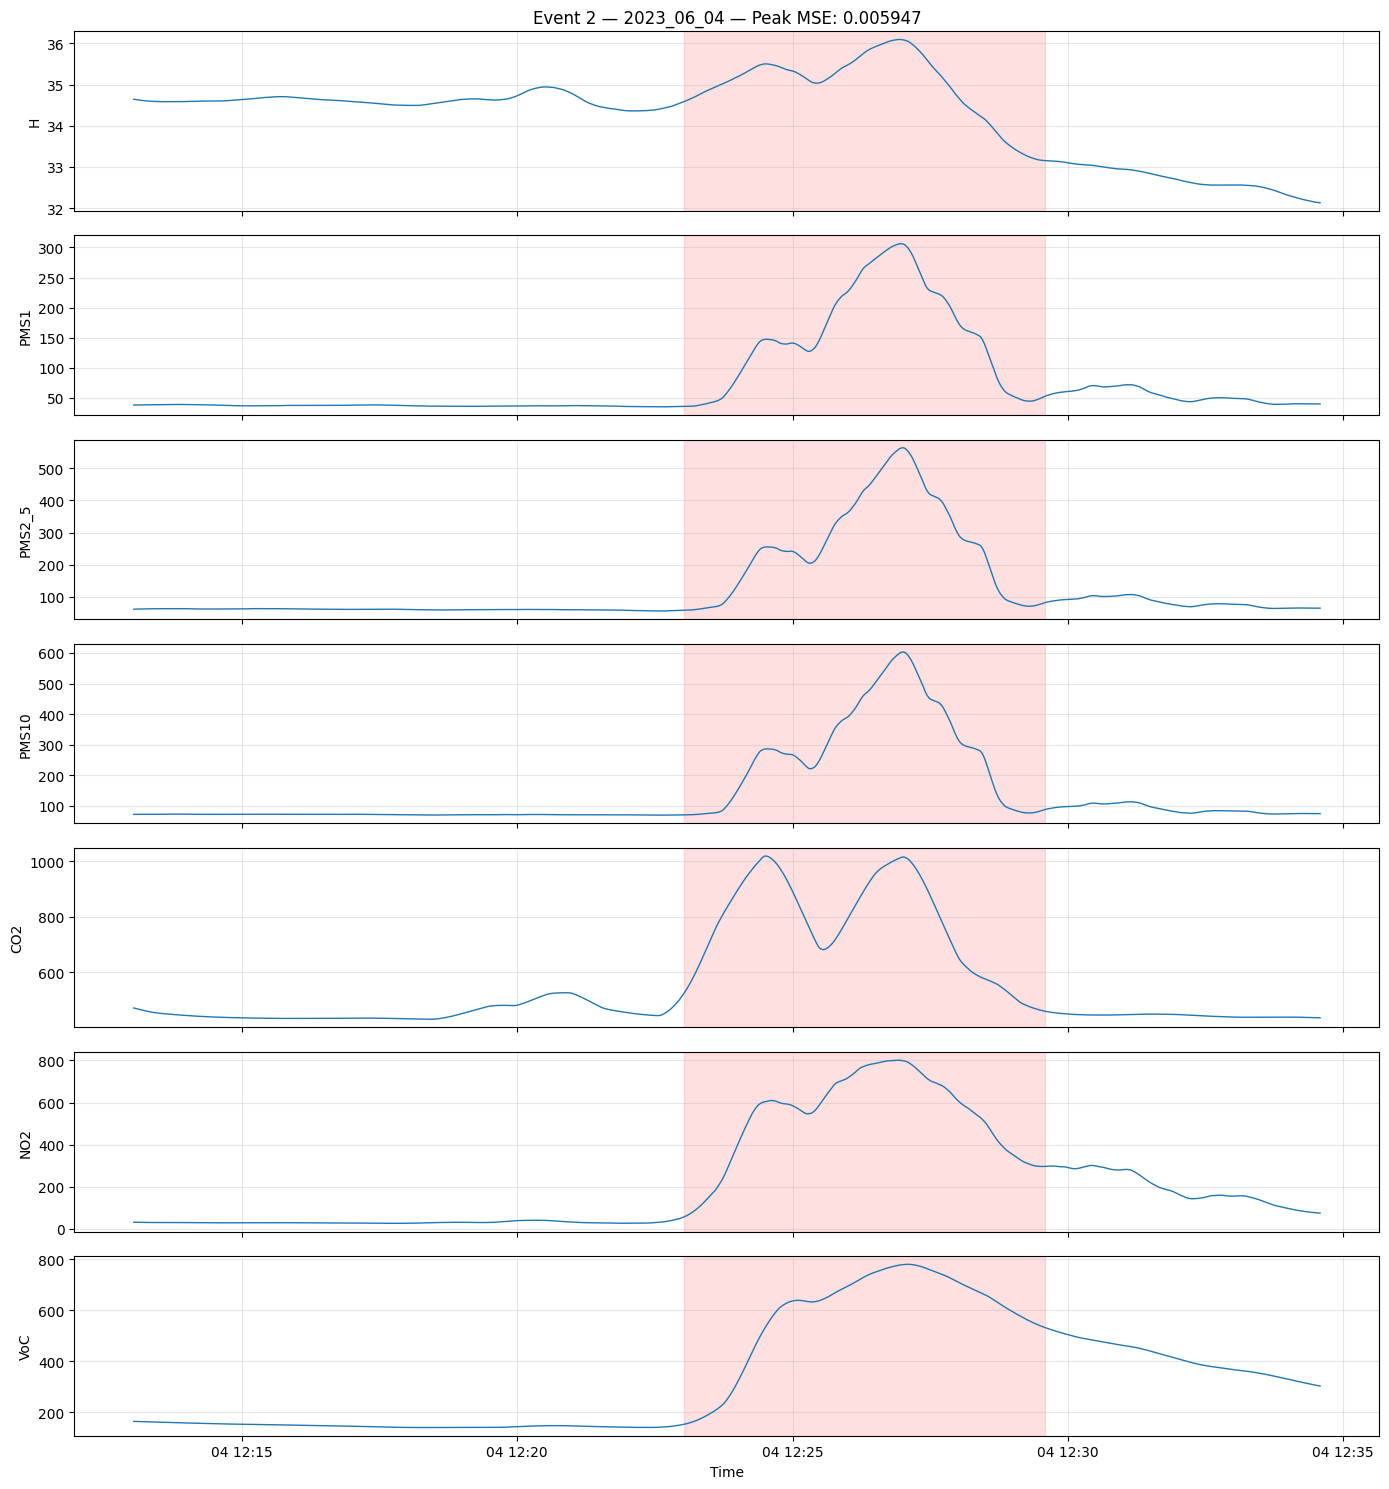

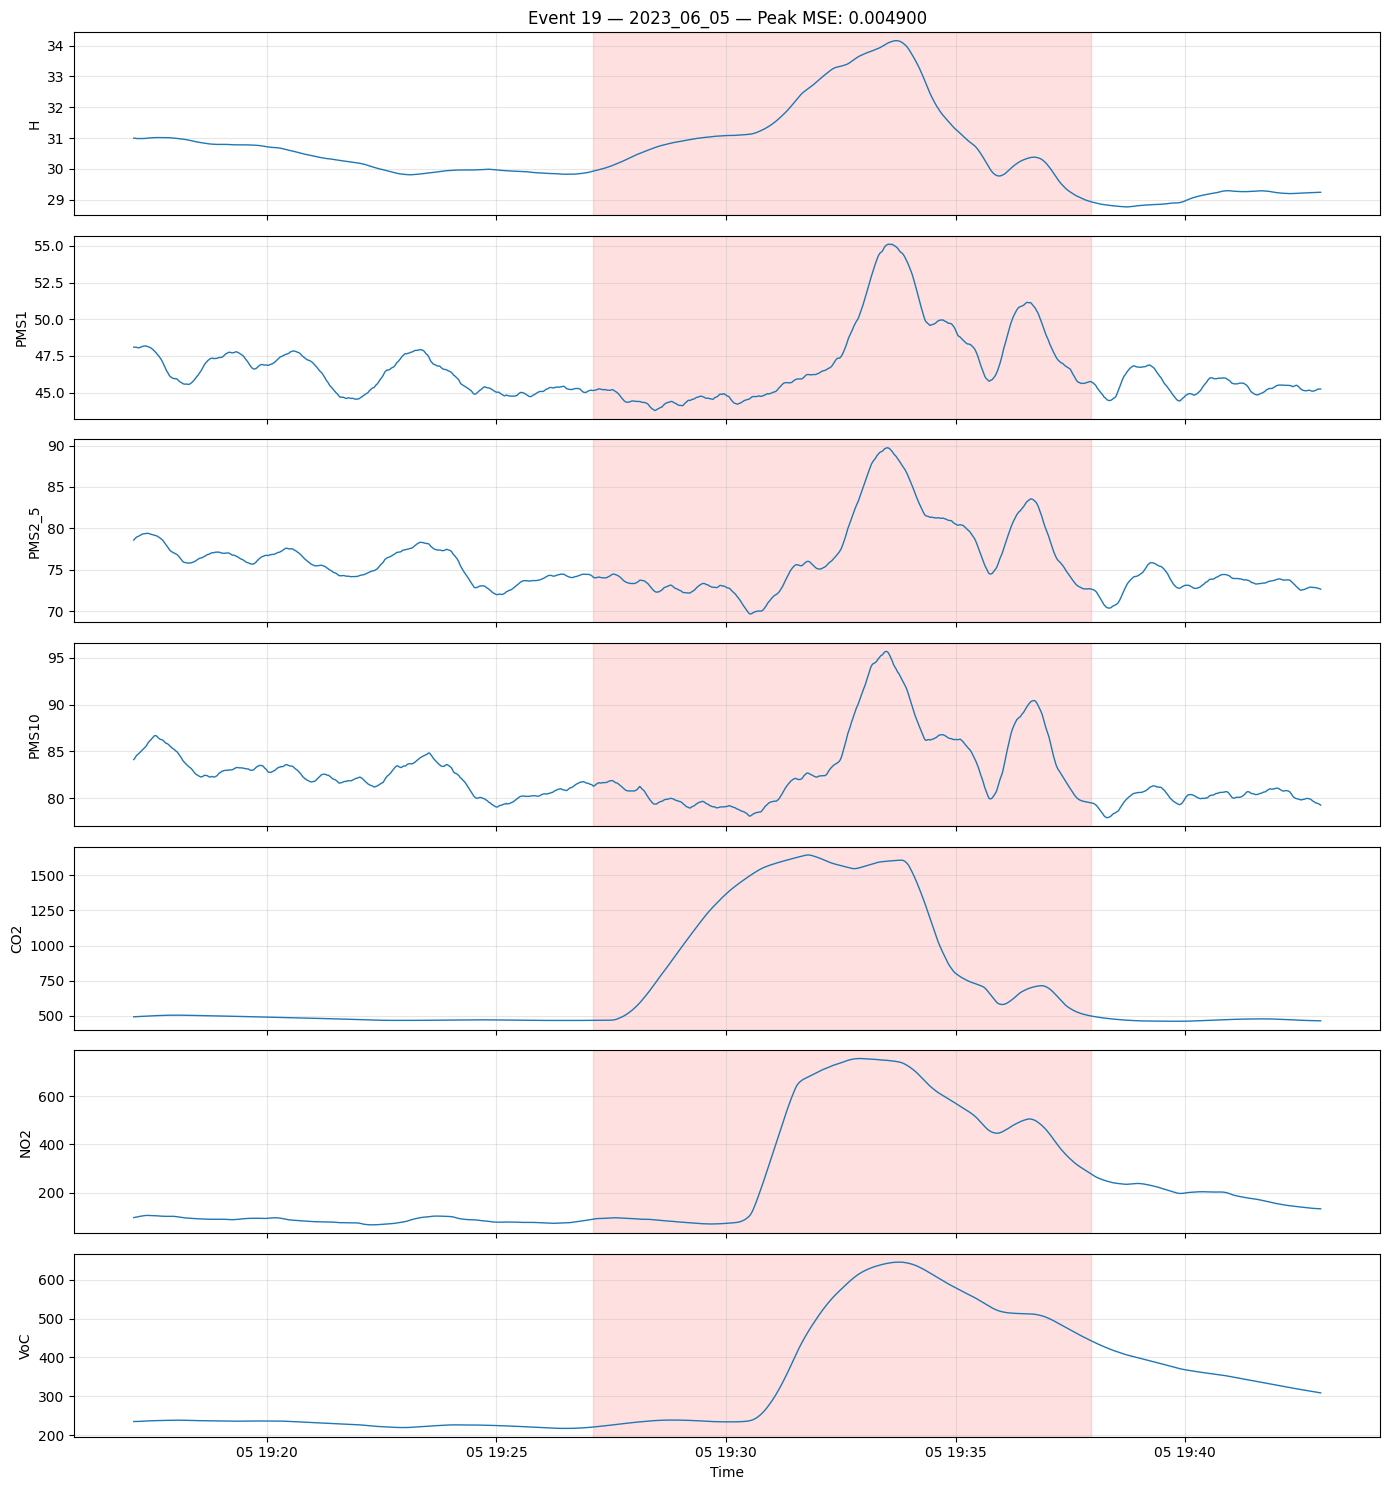


Sensor comparison saved successfully!


In [ ]:
# ============================================================
# STEP 26: ANALYZE ACTUAL SENSOR MEASUREMENTS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Load actual raw sensor recordings
# ------------------------------------------------------------

raw_test_data = {}

for date in TEST_DATES:

    file_path = H1_DIR / date / "41_Kitchen.csv"

    df = pd.read_csv(file_path, low_memory=False)

    df["ts"] = pd.to_datetime(df["ts"])

    for feature in FEATURES:
        df[feature] = pd.to_numeric(
            df[feature], errors="coerce"
        )

    raw_test_data[date] = df.sort_values("ts")

print("Raw test recordings loaded successfully.")

# ------------------------------------------------------------
# 2. Compare sensor measurements around each event
# ------------------------------------------------------------

comparison_rows = []

for _, event in top_events.iterrows():

    date = event["date"]

    # Account for the beginning of the first LSTM window
    event_start = (
        event["first_flagged"]
        - pd.Timedelta(seconds=WINDOW_SIZE - 1)
    )

    event_end = event["last_flagged"]

    baseline_start = (
        event_start - pd.Timedelta(minutes=10)
    )

    df = raw_test_data[date]

    baseline = df[
        (df["ts"] >= baseline_start) &
        (df["ts"] < event_start)
    ]

    during = df[
        (df["ts"] >= event_start) &
        (df["ts"] <= event_end)
    ]

    for feature in FEATURES:

        baseline_mean = baseline[feature].mean()
        event_mean = during[feature].mean()

        comparison_rows.append({
            "event_id": event["event_id"],
            "date": date,
            "feature": feature,
            "baseline_mean": baseline_mean,
            "event_mean": event_mean,
            "absolute_change": event_mean - baseline_mean,
            "relative_change_pct": (
                100 * (event_mean - baseline_mean)
                / abs(baseline_mean)
                if pd.notna(baseline_mean)
                and abs(baseline_mean) > 1e-9
                else np.nan
            )
        })

sensor_comparison = pd.DataFrame(comparison_rows)

print("\nSensor measurement comparison:")
display(sensor_comparison.round(3))

# ------------------------------------------------------------
# 3. Plot actual sensor measurements
# ------------------------------------------------------------

plot_features = [
    "H", "PMS1", "PMS2_5", "PMS10",
    "CO2", "NO2", "VoC"
]

for _, event in top_events.iterrows():

    date = event["date"]

    event_start = (
        event["first_flagged"]
        - pd.Timedelta(seconds=WINDOW_SIZE - 1)
    )

    event_end = event["last_flagged"]

    plot_start = (
        event_start - pd.Timedelta(minutes=10)
    )

    plot_end = (
        event_end + pd.Timedelta(minutes=5)
    )

    df = raw_test_data[date]

    segment = df[
        (df["ts"] >= plot_start) &
        (df["ts"] <= plot_end)
    ]

    fig, axes = plt.subplots(
        len(plot_features),
        1,
        figsize=(14, 15),
        sharex=True
    )

    for ax, feature in zip(axes, plot_features):

        ax.plot(
            segment["ts"],
            segment[feature],
            linewidth=1
        )

        ax.axvspan(
            event_start,
            event_end,
            color="red",
            alpha=0.12
        )

        ax.set_ylabel(feature)
        ax.grid(alpha=0.3)

    axes[0].set_title(
        f"Event {event['event_id']} — "
        f"{date} — Peak MSE: {event['peak_error']:.6f}"
    )

    axes[-1].set_xlabel("Time")

    plt.tight_layout()

    plot_path = (
        PLOTS_DIR /
        f"sensor_event_{int(event['event_id'])}.png"
    )

    plt.savefig(
        plot_path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

# ------------------------------------------------------------
# 4. Save comparisons
# ------------------------------------------------------------

sensor_comparison.to_csv(
    RESULTS_DIR / "top_event_sensor_comparison.csv",
    index=False
)

print("\nSensor comparison saved successfully!")

In [ ]:
# ============================================================
# STEP 27: VERIFY ANOMALY EVENTS WITH SENSOR VALIDITY
#          AND ACTIVITY ANNOTATIONS
# ============================================================

import numpy as np
import pandas as pd

verification_records = []
nearby_activity_records = []

for _, event in top_events.iterrows():

    event_id = int(event["event_id"])
    date = event["date"]

    # Include the full first LSTM window
    start = (
        event["first_flagged"]
        - pd.Timedelta(seconds=WINDOW_SIZE - 1)
    )
    end = event["last_flagged"]

    df = raw_test_data[date]

    event_data = df[
        (df["ts"] >= start) &
        (df["ts"] <= end)
    ].copy()

    valid = (
        (pd.to_numeric(
            event_data["Valid"], errors="coerce"
        ) == 1) &
        (pd.to_numeric(
            event_data["Valid_CO2"], errors="coerce"
        ) == 1)
    )

    finite = np.isfinite(
        event_data[FEATURES]
    ).all(axis=1)

    all_zero = event_data[FEATURES].eq(0).all(axis=1)

    verification_records.append({
        "event_id": event_id,
        "date": date,
        "start": start,
        "end": end,
        "sensor_rows": len(event_data),
        "valid_flag_pct": round(100 * valid.mean(), 2),
        "finite_pct": round(100 * finite.mean(), 2),
        "all_zero_rows": int(all_zero.sum()),
        "peak_error": event["peak_error"]
    })

    # Find activity annotations within +/- 10 minutes
    nearby = h1_activities[
        (h1_activities["ts"] >=
         start - pd.Timedelta(minutes=10)) &
        (h1_activities["ts"] <=
         end + pd.Timedelta(minutes=10))
    ]

    for _, activity in nearby.iterrows():

        nearby_activity_records.append({
            "event_id": event_id,
            "event_date": date,
            "activity_time": activity["ts"],
            "activity": activity["Label"],
            "customer": activity["Customer"],
            "during_event": (
                start <= activity["ts"] <= end
            )
        })

# Display verification results
verification_df = pd.DataFrame(verification_records)

activity_matches_df = pd.DataFrame(
    nearby_activity_records,
    columns=[
        "event_id", "event_date", "activity_time",
        "activity", "customer", "during_event"
    ]
)

print("=" * 60)
print("SENSOR VALIDITY VERIFICATION")
print("=" * 60)

display(verification_df)

print("\n" + "=" * 60)
print("NEARBY ACTIVITY ANNOTATIONS")
print("=" * 60)

if activity_matches_df.empty:
    print("No nearby annotations found.")
else:
    display(activity_matches_df)

    print("\nNearby annotation counts by event:")
    display(
        activity_matches_df.groupby("event_id")
        .agg(
            nearby_annotations=("activity", "size"),
            during_event=("during_event", "sum")
        )
    )

# Save results
verification_df.to_csv(
    RESULTS_DIR / "event_validity_verification.csv",
    index=False
)

activity_matches_df.to_csv(
    RESULTS_DIR / "event_activity_matches.csv",
    index=False
)

print("\nSTEP 27 verification results saved!")

SENSOR VALIDITY VERIFICATION


,event_id,date,start,end,sensor_rows,valid_flag_pct,finite_pct,all_zero_rows,peak_error
0,23,2023_06_05,2023-06-05 22:25:51,2023-06-05 22:33:00,430,100.0,100.0,0,0.009903
1,20,2023_06_05,2023-06-05 21:30:07,2023-06-05 21:35:53,347,100.0,100.0,0,0.006812
2,8,2023_06_04,2023-06-04 14:54:57,2023-06-04 16:15:29,4833,100.0,100.0,0,0.006090
3,2,2023_06_04,2023-06-04 12:23:02,2023-06-04 12:29:35,394,100.0,100.0,0,0.005947
4,19,2023_06_05,2023-06-05 19:27:06,2023-06-05 19:37:57,652,100.0,100.0,0,0.004900



NEARBY ACTIVITY ANNOTATIONS


,event_id,event_date,activity_time,activity,customer,during_event
0,23,2023_06_05,2023-06-05 22:23:05,making roti,P1,False
1,23,2023_06_05,2023-06-05 22:29:53,complete,P1,True
2,23,2023_06_05,2023-06-05 22:30:15,bedroom fan off,P1,True
3,23,2023_06_05,2023-06-05 22:31:51,cutting mango,P1,True
4,23,2023_06_05,2023-06-05 22:32:07,eating dinner,P1,True
5,20,2023_06_05,2023-06-05 21:30:51,frying onion ginger garlic and heating dal,P1,True
6,20,2023_06_05,2023-06-05 21:36:07,complete,P1,False
7,8,2023_06_04,2023-06-04 16:11:54,bedroom fan off,P2,True
8,8,2023_06_04,2023-06-04 16:21:50,making tea,P2,False
9,8,2023_06_04,2023-06-04 16:24:55,dining fan on,P1,False



Nearby annotation counts by event:


,nearby_annotations,during_event
event_id,,
2,6,2
8,4,1
19,3,0
20,2,1
23,5,4



STEP 27 verification results saved!


In [ ]:
# ============================================================
# ONE-CELL RESTORE: IAQ LSTM AUTOENCODER PROJECT
# ============================================================

import os
import subprocess
import numpy as np
import pandas as pd
import tensorflow as tf

from pathlib import Path
from sklearn.preprocessing import MinMaxScaler

# ------------------------------------------------------------
# 1. PROJECT CONFIGURATION
# ------------------------------------------------------------

PROJECT_DIR = Path("/content/IAQ_Anomaly_Detection")
REPO_DIR = PROJECT_DIR / "DALTON"
PROCESSED_DIR = REPO_DIR / "Processed"
H1_DIR = PROCESSED_DIR / "H1"

MODEL_DIR = PROJECT_DIR / "models"
RESULTS_DIR = PROJECT_DIR / "results"
PLOTS_DIR = PROJECT_DIR / "plots"

for directory in [PROJECT_DIR, MODEL_DIR, RESULTS_DIR, PLOTS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

FEATURES = [
    "T", "H", "PMS1", "PMS2_5", "PMS10",
    "CO2", "NO2", "CO", "VoC", "C2H5OH"
]

WINDOW_SIZE = 60

TRAIN_DATES = [
    "2023_05_28",
    "2023_05_29",
    "2023_05_30"
]

VAL_DATES = ["2023_05_31"]

TEST_DATES = [
    "2023_06_04",
    "2023_06_05"
]

# ------------------------------------------------------------
# 2. CHECK / RESTORE DATASET
# ------------------------------------------------------------

required_file = H1_DIR / "2023_05_28" / "41_Kitchen.csv"

def is_real_csv(path):
    if not path.is_file() or path.stat().st_size < 1000:
        return False
    with path.open("rb") as f:
        return f.readline().startswith(b"ts,")

if not is_real_csv(required_file):

    print("Restoring DALTON dataset...")

    subprocess.run(
        ["apt-get", "update", "-qq"],
        check=True
    )

    subprocess.run(
        ["apt-get", "install", "-y", "-qq", "git-lfs"],
        check=True
    )

    subprocess.run(["git", "lfs", "install"], check=True)

    if not (REPO_DIR / ".git").exists():

        if REPO_DIR.exists():
            import shutil
            shutil.rmtree(REPO_DIR)

        subprocess.run(
            [
                "git", "clone", "--depth", "1",
                "https://github.com/prasenjit52282/dalton-dataset.git",
                str(REPO_DIR)
            ],
            check=True
        )

    subprocess.run(
        ["git", "-C", str(REPO_DIR), "lfs", "pull"],
        check=True
    )

assert all(
    is_real_csv(H1_DIR / d / "41_Kitchen.csv")
    for d in TRAIN_DATES + VAL_DATES + TEST_DATES
), "Some DALTON CSV files are missing or still Git LFS pointers."

print("DALTON dataset ready.")

# ------------------------------------------------------------
# 3. CLEAN RECORDINGS
# ------------------------------------------------------------

def load_clean_recordings(dates):
    recordings = []

    for date in dates:

        file_path = H1_DIR / date / "41_Kitchen.csv"

        df = pd.read_csv(
            file_path,
            low_memory=False
        )

        df["ts"] = pd.to_datetime(
            df["ts"], errors="coerce"
        )

        for feature in FEATURES:
            df[feature] = pd.to_numeric(
                df[feature], errors="coerce"
            )

        valid = (
            (pd.to_numeric(df["Valid"], errors="coerce") == 1) &
            (pd.to_numeric(df["Valid_CO2"], errors="coerce") == 1) &
            np.isfinite(df[FEATURES]).all(axis=1) &
            ~df[FEATURES].eq(0).all(axis=1) &
            df["ts"].notna()
        )

        clean = df.loc[
            valid, ["ts"] + FEATURES
        ].copy()

        clean["recording_date"] = date

        gaps = (
            clean.index.to_series().diff().ne(1) |
            clean["ts"].diff().ne(pd.Timedelta(seconds=1))
        )

        clean["segment_id"] = gaps.cumsum()

        recordings.append(clean)

        print(
            f"{date}: {len(clean):,} readings, "
            f"{clean['segment_id'].nunique()} segments"
        )

    return recordings


print("\nLoading training data...")
train_recordings = load_clean_recordings(TRAIN_DATES)

print("\nLoading validation data...")
val_recordings = load_clean_recordings(VAL_DATES)

print("\nLoading test data...")
test_recordings = load_clean_recordings(TEST_DATES)

# ------------------------------------------------------------
# 4. NORMALIZATION
# ------------------------------------------------------------

train_values = pd.concat(
    [df[FEATURES] for df in train_recordings],
    ignore_index=True
)

scaler = MinMaxScaler()
scaler.fit(train_values)

print("\nScaler fitted on training readings only.")

# ------------------------------------------------------------
# 5. CREATE LSTM SEQUENCES
# ------------------------------------------------------------

def create_sequences(recordings, scaler, window_size=60):

    sequences = []
    metadata = []

    for recording in recordings:

        date = recording["recording_date"].iloc[0]

        for segment_id, segment in recording.groupby(
            "segment_id", sort=False
        ):

            if len(segment) < window_size:
                continue

            values = scaler.transform(
                segment[FEATURES]
            ).astype(np.float32)

            windows = np.lib.stride_tricks.sliding_window_view(
                values,
                window_shape=window_size,
                axis=0
            ).transpose(0, 2, 1).copy()

            sequences.append(windows)

            timestamps = segment["ts"].to_numpy()

            metadata.extend([
                {
                    "date": date,
                    "timestamp": timestamps[i + window_size - 1],
                    "segment_id": int(segment_id)
                }
                for i in range(len(windows))
            ])

    return (
        np.concatenate(sequences, axis=0),
        pd.DataFrame(metadata)
    )


print("\nGenerating sequences...")

X_train, train_metadata = create_sequences(
    train_recordings, scaler, WINDOW_SIZE
)

X_val, val_metadata = create_sequences(
    val_recordings, scaler, WINDOW_SIZE
)

X_test, test_metadata = create_sequences(
    test_recordings, scaler, WINDOW_SIZE
)

# ------------------------------------------------------------
# 6. LOAD EXISTING TRAINED MODEL
# ------------------------------------------------------------

model_path = MODEL_DIR / "best_iaq_lstm_autoencoder.keras"

if model_path.exists():

    best_model = tf.keras.models.load_model(str(model_path))
    autoencoder = best_model

    print("\nTrained LSTM Autoencoder loaded successfully!")

else:

    best_model = None

    print("\nWARNING: Saved LSTM model not found.")
    print("Restore the model from your backup ZIP.")
    print("No retraining was performed.")

# ------------------------------------------------------------
# 7. FINAL VERIFICATION
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("PROJECT RESTORATION SUMMARY")
print("=" * 60)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nTraining NaNs:", np.isnan(X_train).sum())
print("Validation NaNs:", np.isnan(X_val).sum())
print("Testing NaNs:", np.isnan(X_test).sum())

print("\nGPU:", tf.config.list_physical_devices("GPU"))

print("\nData preparation completed.")
print("Ready for Isolation Forest baseline preparation.")

Restoring DALTON dataset...
DALTON dataset ready.

Loading training data...
2023_05_28: 86,341 readings, 1 segments
2023_05_29: 86,341 readings, 1 segments
2023_05_30: 73,563 readings, 2 segments

Loading validation data...
2023_05_31: 86,341 readings, 1 segments

Loading test data...
2023_06_04: 86,341 readings, 1 segments
2023_06_05: 86,341 readings, 1 segments

Scaler fitted on training readings only.

Generating sequences...

Restore the model from your backup ZIP.
No retraining was performed.

PROJECT RESTORATION SUMMARY
Training: (246009, 60, 10)
Validation: (86282, 60, 10)
Testing: (172564, 60, 10)

Training NaNs: 0
Validation NaNs: 0
Testing NaNs: 0

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Data preparation completed.
Ready for Isolation Forest baseline preparation.


In [ ]:
# ============================================================
# STEP 28A: LOCATE PREVIOUSLY TRAINED LSTM MODEL
# ============================================================

from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

MODEL_FILENAME = "best_iaq_lstm_autoencoder.keras"

search_locations = [
    Path("/content/IAQ_Anomaly_Detection/models"),
    Path("/content/drive/MyDrive")
]

found_models = []

for root in search_locations:

    if not root.exists():
        continue

    print(f"\nSearching: {root}")

    for path in root.rglob(MODEL_FILENAME):
        found_models.append(path)
        print("FOUND:", path)
        print("Size (MB):", round(path.stat().st_size / 1024**2, 2))

print("\n" + "=" * 55)

if found_models:
    print("Saved model found!")
    print("Number of matching files:", len(found_models))
else:
    print("Saved model not found in the searched locations.")
    print("Check whether you downloaded IAQ_Project_Backup.zip.")

Mounted at /content/drive

Searching: /content/IAQ_Anomaly_Detection/models

Searching: /content/drive/MyDrive

Saved model not found in the searched locations.
Check whether you downloaded IAQ_Project_Backup.zip.


In [ ]:
# ============================================================
# STEP 28B: PREPARE ISOLATION FOREST BASELINE DATA
# ============================================================

import numpy as np
from sklearn.preprocessing import StandardScaler

def extract_statistical_features(X):
    """
    Converts 60x10 sensor sequences into
    40 statistical features per sequence.
    """
    return np.concatenate([
        np.mean(X, axis=1),
        np.std(X, axis=1),
        np.min(X, axis=1),
        np.max(X, axis=1)
    ], axis=1).astype(np.float32)


# Use every 60th training sequence to reduce
# overlap and computational cost.
train_indices = []

for date in TRAIN_DATES:
    indices = np.flatnonzero(
        train_metadata["date"].to_numpy() == date
    )
    train_indices.extend(indices[::WINDOW_SIZE])

train_indices = np.asarray(train_indices, dtype=int)

# Extract statistical features
X_train_if_raw = extract_statistical_features(
    X_train[train_indices]
)

X_val_if_raw = extract_statistical_features(X_val)
X_test_if_raw = extract_statistical_features(X_test)

# Fit feature scaler only on training data
if_scaler = StandardScaler()

X_train_if = if_scaler.fit_transform(X_train_if_raw)
X_val_if = if_scaler.transform(X_val_if_raw)
X_test_if = if_scaler.transform(X_test_if_raw)

print("=" * 55)
print("ISOLATION FOREST DATA PREPARATION")
print("=" * 55)

print("Training:", X_train_if.shape)
print("Validation:", X_val_if.shape)
print("Testing:", X_test_if.shape)

print("\nAll values finite:")
print("Training:", np.isfinite(X_train_if).all())
print("Validation:", np.isfinite(X_val_if).all())
print("Testing:", np.isfinite(X_test_if).all())

ISOLATION FOREST DATA PREPARATION
Training: (4103, 40)
Validation: (86282, 40)
Testing: (172564, 40)

All values finite:
Training: True
Validation: True
Testing: True


Training Isolation Forest...
Isolation Forest training completed!

Validation-based threshold: 0.6025597955256119

Isolation Forest anomaly detection summary:


,Dataset,Total sequences,Detected anomalies,Anomaly percentage
0,Training,4103,70,1.706069
1,Validation,86282,863,1.000209
2,Testing,172564,2251,1.304444


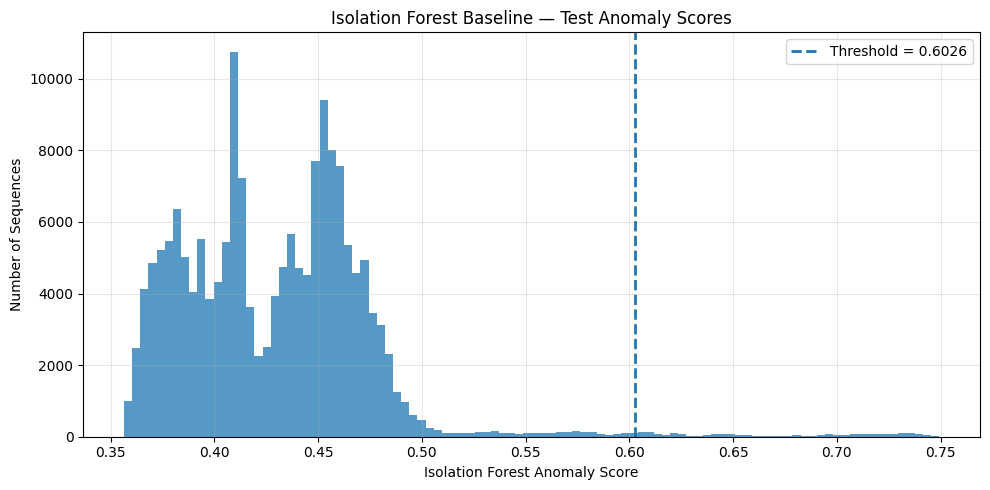


Baseline model and results saved successfully!


In [ ]:
# ============================================================
# STEP 29: TRAIN AND EVALUATE ISOLATION FOREST BASELINE
# ============================================================

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest

# ------------------------------------------------------------
# 1. Train Isolation Forest
# ------------------------------------------------------------

if_model = IsolationForest(
    n_estimators=200,
    max_samples=min(2048, len(X_train_if)),
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

print("Training Isolation Forest...")
if_model.fit(X_train_if)

print("Isolation Forest training completed!")

# ------------------------------------------------------------
# 2. Compute anomaly scores
# ------------------------------------------------------------

# Higher score = more anomalous
train_if_scores = -if_model.score_samples(X_train_if)
val_if_scores = -if_model.score_samples(X_val_if)
test_if_scores = -if_model.score_samples(X_test_if)

# ------------------------------------------------------------
# 3. Calibrate threshold using validation data
# ------------------------------------------------------------

IF_THRESHOLD_PERCENTILE = 99

if_threshold = np.percentile(
    val_if_scores,
    IF_THRESHOLD_PERCENTILE
)

print("\nValidation-based threshold:", if_threshold)

# ------------------------------------------------------------
# 4. Predict anomalies
# ------------------------------------------------------------

train_if_anomalies = train_if_scores > if_threshold
val_if_anomalies = val_if_scores > if_threshold
test_if_anomalies = test_if_scores > if_threshold

# ------------------------------------------------------------
# 5. Summarize detection results
# ------------------------------------------------------------

if_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "Total sequences": [
        len(train_if_scores),
        len(val_if_scores),
        len(test_if_scores)
    ],
    "Detected anomalies": [
        int(train_if_anomalies.sum()),
        int(val_if_anomalies.sum()),
        int(test_if_anomalies.sum())
    ]
})

if_summary["Anomaly percentage"] = (
    100 * if_summary["Detected anomalies"]
    / if_summary["Total sequences"]
)

print("\nIsolation Forest anomaly detection summary:")
display(if_summary)

# ------------------------------------------------------------
# 6. Save baseline model and results
# ------------------------------------------------------------

joblib.dump(
    if_model,
    MODEL_DIR / "isolation_forest_baseline.joblib"
)

joblib.dump(
    if_scaler,
    MODEL_DIR / "isolation_forest_scaler.joblib"
)

if_summary.to_csv(
    RESULTS_DIR / "isolation_forest_summary.csv",
    index=False
)

if_results = test_metadata.copy()

if_results["anomaly_score"] = test_if_scores
if_results["threshold"] = if_threshold
if_results["predicted_anomaly"] = (
    test_if_anomalies.astype(int)
)

if_results.to_csv(
    RESULTS_DIR / "isolation_forest_test_predictions.csv",
    index=False
)

# ------------------------------------------------------------
# 7. Visualize test anomaly scores
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.hist(
    test_if_scores,
    bins=100,
    alpha=0.75
)

plt.axvline(
    if_threshold,
    linestyle="--",
    linewidth=2,
    label=f"Threshold = {if_threshold:.4f}"
)

plt.xlabel("Isolation Forest Anomaly Score")
plt.ylabel("Number of Sequences")
plt.title("Isolation Forest Baseline — Test Anomaly Scores")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "isolation_forest_anomaly_scores.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nBaseline model and results saved successfully!")

ISOLATION FOREST SYNTHETIC EVALUATION
Accuracy : 64.53%
Precision: 95.46%
Recall   : 30.50%
F1-score : 46.23%

Confusion matrix:
TN: 1971 FP: 29
FN: 1390 TP: 610


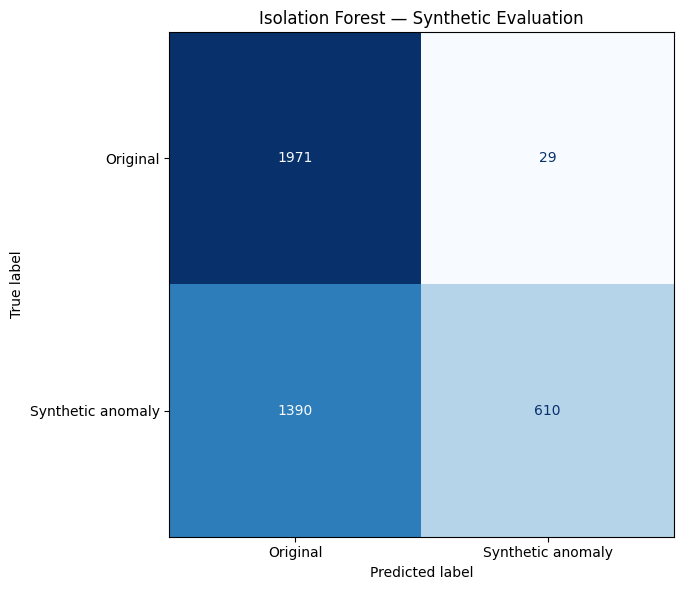


Results by sample type:


,type,count,sum,mean,detection_pct
0,noise,666,212,0.318318,31.831832
1,original,2000,29,0.014500,1.450000
2,spike,667,207,0.310345,31.034483
3,sustained_shift,667,191,0.286357,28.635682



Baseline evaluation saved successfully!


In [ ]:
# ============================================================
# STEP 30: ISOLATION FOREST SYNTHETIC EVALUATION
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# ------------------------------------------------------------
# 1. Recreate STEP 21 evaluation window selection
# ------------------------------------------------------------

rng_selection = np.random.default_rng(2026)

candidate_indices = []

for date in sorted(test_metadata["date"].unique()):
    day_indices = np.flatnonzero(
        test_metadata["date"].to_numpy() == date
    )
    candidate_indices.extend(day_indices[::WINDOW_SIZE])

candidate_indices = np.asarray(candidate_indices, dtype=int)

selected_indices = np.sort(
    rng_selection.choice(
        candidate_indices,
        size=2000,
        replace=False
    )
)

X_independent_base = X_test[selected_indices].copy()

# ------------------------------------------------------------
# 2. Recreate STEP 22 injected anomalies
# ------------------------------------------------------------

rng_injection = np.random.default_rng(2026)

X_original = X_independent_base.copy()
X_modified = X_independent_base.copy()

N = len(X_modified)
SEQ_LEN = X_modified.shape[1]
N_FEATURES = X_modified.shape[2]

anomaly_types = ["spike", "sustained_shift", "noise"]
anomaly_types_independent = []

for i in range(N):

    anomaly_type = anomaly_types[i % len(anomaly_types)]
    anomaly_types_independent.append(anomaly_type)

    features_to_modify = rng_injection.choice(
        N_FEATURES,
        size=int(rng_injection.integers(1, 4)),
        replace=False
    )

    if anomaly_type == "spike":

        duration = int(rng_injection.integers(5, 11))
        start = int(
            rng_injection.integers(0, SEQ_LEN - duration + 1)
        )
        amplitude = rng_injection.uniform(0.5, 1.0)

        X_modified[
            i, start:start + duration, features_to_modify
        ] += amplitude

    elif anomaly_type == "sustained_shift":

        duration = int(rng_injection.integers(20, 41))
        start = int(
            rng_injection.integers(0, SEQ_LEN - duration + 1)
        )
        amplitude = rng_injection.uniform(0.25, 0.6)

        X_modified[
            i, start:start + duration, features_to_modify
        ] += amplitude

    elif anomaly_type == "noise":

        noise = rng_injection.normal(
            loc=0.0,
            scale=0.3,
            size=(SEQ_LEN, len(features_to_modify))
        )

        X_modified[i][:, features_to_modify] += noise

X_independent_eval = np.concatenate(
    [X_original, X_modified],
    axis=0
).astype(np.float32)

y_independent_eval = np.concatenate([
    np.zeros(N, dtype=int),
    np.ones(N, dtype=int)
])

evaluation_types = np.array(
    ["original"] * N + anomaly_types_independent
)

permutation = rng_injection.permutation(
    len(X_independent_eval)
)

X_independent_eval = X_independent_eval[permutation]
y_independent_eval = y_independent_eval[permutation]
evaluation_types = evaluation_types[permutation]

# ------------------------------------------------------------
# 3. Extract statistical features
# ------------------------------------------------------------

X_eval_if_raw = extract_statistical_features(
    X_independent_eval
)

X_eval_if = if_scaler.transform(X_eval_if_raw)

# ------------------------------------------------------------
# 4. Predict with Isolation Forest
# ------------------------------------------------------------

if_eval_scores = -if_model.score_samples(X_eval_if)

y_pred_if = (
    if_eval_scores > if_threshold
).astype(int)

# ------------------------------------------------------------
# 5. Calculate baseline classification metrics
# ------------------------------------------------------------

if_accuracy = accuracy_score(
    y_independent_eval, y_pred_if
)

if_precision = precision_score(
    y_independent_eval, y_pred_if,
    zero_division=0
)

if_recall = recall_score(
    y_independent_eval, y_pred_if,
    zero_division=0
)

if_f1 = f1_score(
    y_independent_eval, y_pred_if,
    zero_division=0
)

print("=" * 60)
print("ISOLATION FOREST SYNTHETIC EVALUATION")
print("=" * 60)

print(f"Accuracy : {if_accuracy * 100:.2f}%")
print(f"Precision: {if_precision * 100:.2f}%")
print(f"Recall   : {if_recall * 100:.2f}%")
print(f"F1-score : {if_f1 * 100:.2f}%")

# ------------------------------------------------------------
# 6. Confusion matrix
# ------------------------------------------------------------

cm_if = confusion_matrix(
    y_independent_eval,
    y_pred_if,
    labels=[0, 1]
)

tn, fp, fn, tp = cm_if.ravel()

print("\nConfusion matrix:")
print("TN:", tn, "FP:", fp)
print("FN:", fn, "TP:", tp)

fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay(
    confusion_matrix=cm_if,
    display_labels=["Original", "Synthetic anomaly"]
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Isolation Forest — Synthetic Evaluation")
plt.tight_layout()

plt.savefig(
    PLOTS_DIR / "isolation_forest_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 7. Detection by anomaly type
# ------------------------------------------------------------

type_df = pd.DataFrame({
    "type": evaluation_types,
    "predicted_anomaly": y_pred_if
})

type_summary_if = (
    type_df.groupby("type")["predicted_anomaly"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

type_summary_if["detection_pct"] = (
    type_summary_if["mean"] * 100
)

print("\nResults by sample type:")
display(type_summary_if)

# ------------------------------------------------------------
# 8. Save baseline results
# ------------------------------------------------------------

baseline_metrics = pd.DataFrame([{
    "model": "Isolation Forest",
    "accuracy": if_accuracy,
    "precision": if_precision,
    "recall": if_recall,
    "f1_score": if_f1,
    "threshold": if_threshold
}])

baseline_metrics.to_csv(
    RESULTS_DIR / "isolation_forest_synthetic_metrics.csv",
    index=False
)

type_summary_if.to_csv(
    RESULTS_DIR / "isolation_forest_anomaly_types.csv",
    index=False
)

print("\nBaseline evaluation saved successfully!")

In [1]:
from pathlib import Path

model_path = Path(
    "/content/IAQ_Anomaly_Detection/models/"
    "best_iaq_lstm_autoencoder.keras"
)

if model_path.exists():
    print("Saved trained model found!")

    from google.colab import files
    files.download(str(model_path))
else:
    print("Model not found in this Colab runtime.")

Model not found in this Colab runtime.


In [2]:
from pathlib import Path

print("Searching for saved trained models...\n")

extensions = {".keras", ".h5", ".hdf5", ".joblib", ".pkl"}

found = []

for path in Path("/content").rglob("*"):
    if path.is_file() and path.suffix.lower() in extensions:
        found.append(path)
        print(f"FOUND: {path}")

if not found:
    print("No saved model files found in /content.")

Searching for saved trained models...

No saved model files found in /content.
